## **BANK MARKETING CAMPAIGN**

Created by `Rayhan Akmal Hidayat`  

## Prediksi Potensi Nasabah Berlangganan Deposito Sebelum Kampanye Pemasaran

Notebook ini membangun model klasifikasi untuk memperkirakan apakah seorang nasabah berpotensi berlangganan deposito berjangka (`yes` atau `no`) **sebelum kampanye pemasaran saat ini dimulai**.

Model dirancang sebagai alat bantu bagi tim pemasaran dalam menyusun prioritas nasabah. Seluruh fitur input harus merupakan informasi yang diasumsikan telah tersedia pada titik waktu prediksi.

**Catatan:** Skenario pre-campaign merupakan asumsi penggunaan model. Dokumentasi dataset tidak memberikan timestamp terperinci untuk setiap kolom, sehingga ketersediaan fitur perlu diverifikasi sebelum model diterapkan pada sistem operasional.


### **1. BUSINESS UNDERSTANDING**

**BUSINESS BACKGROUND**

Bank menawarkan produk deposito berjangka (*term deposit*), yaitu produk simpanan yang hanya dapat ditarik setelah periode tertentu dan memberikan imbal hasil sesuai ketentuan bank. Untuk memperoleh nasabah, bank dapat melakukan kegiatan pemasaran melalui berbagai saluran komunikasi.

Salah satu tantangan tim pemasaran adalah menentukan nasabah yang perlu diprioritaskan sebelum kampanye dimulai. Pendekatan pemasaran yang hanya mengandalkan pemilihan secara umum dapat menyebabkan sumber daya pemasaran tidak terarah.

Dengan memanfaatkan data profil nasabah serta riwayat interaksi dari kampanye sebelumnya, bank dapat membangun model klasifikasi untuk memperkirakan potensi nasabah berlangganan deposito. Hasil prediksi dapat menjadi informasi pendukung dalam menyusun prioritas kegiatan pemasaran, bukan sebagai keputusan otomatis.


**PROBLEM STATEMENT**

Tim pemasaran bank perlu menentukan nasabah yang berpotensi berlangganan deposito sebelum kampanye pemasaran saat ini dilaksanakan. Namun, keputusan prioritas nasabah dapat sulit dilakukan apabila hanya mengandalkan penilaian manual atau informasi yang terbatas.

Permasalahan yang diangkat dalam proyek ini adalah bagaimana membangun model klasifikasi yang dapat memperkirakan kemungkinan nasabah berlangganan deposito berdasarkan informasi yang diasumsikan telah tersedia sebelum kampanye saat ini dimulai.

Untuk menjaga kesesuaian dengan skenario tersebut, fitur yang baru terbentuk selama atau setelah kampanye saat ini tidak digunakan sebagai input model.


**GOALS**

1. Membangun model klasifikasi untuk memprediksi potensi nasabah berlangganan deposito (`yes` atau `no`) sebelum kampanye pemasaran saat ini dimulai.
2. Menggunakan profil nasabah dan informasi historis dari kampanye sebelumnya sebagai kandidat fitur prediksi.
3. Membandingkan beberapa algoritma klasifikasi menggunakan metrik evaluasi yang sesuai dengan kebutuhan bisnis.
4. Menentukan model dan ambang batas klasifikasi yang dapat membantu tim pemasaran menyusun prioritas nasabah.


**Target**

- `no`: Nasabah tidak melakukan berlangganan term deposit.
- `yes`: Nasabah melakukan berlangganan term deposit.

**STAKEHOLDER**

| Pemangku Kepentingan | Peran |
|---|---|
| Manajemen Bank | Menggunakan ringkasan hasil prediksi untuk mendukung perencanaan strategi pemasaran. |
| Tim Pemasaran | Memanfaatkan skor prediksi untuk membantu menyusun prioritas nasabah sebelum kampanye dimulai. |


**BUSINESS SUCCES CRITERIA**

1. Model mampu membedakan nasabah yang berpotensi dan tidak berpotensi berlangganan deposito berdasarkan nilai ROC AUC.
2. Precision, Recall, dan F1-Score digunakan untuk mengevaluasi kualitas prediksi pada ambang batas yang dipilih.
3. Recall perlu diperhatikan agar sebanyak mungkin nasabah yang berpotensi berlangganan dapat teridentifikasi, sedangkan Precision membantu menilai ketepatan daftar nasabah prioritas.
4. Seluruh fitur input harus sesuai dengan titik waktu penggunaan model, yaitu sebelum kampanye pemasaran saat ini dimulai.


**POTENTIAL BUSINESS RISKS & EVALUATION METRICS**

| Kesalahan Klasifikasi | Potensi Interpretasi |
|---|---|
| False Positive | Nasabah diprediksi berpotensi berlangganan, tetapi pada kenyataannya tidak berlangganan. Tim pemasaran dapat mengalokasikan upaya kepada nasabah yang tidak merespons penawaran. |
| False Negative | Nasabah diprediksi tidak berpotensi, tetapi pada kenyataannya berlangganan. Bank berisiko melewatkan calon nasabah yang potensial. |

ROC AUC digunakan untuk mengukur kemampuan model membedakan kedua kelas pada berbagai threshold. Precision, Recall, dan F1-Score digunakan untuk memahami konsekuensi kesalahan klasifikasi pada threshold operasional.  

Berdasarkan konsekuensi dari permasalahan bisnis tersebut, maka sebisa mungkin kita ingin membangun model yang dapat meningkatkan efektivitas marketing campaign dengan mengurangi biaya dan sumber daya yang digunakan untuk menghubungi nasabah yang tidak tertarik melakukan deposito berjangka. Namun, hal tersebut juga tidak boleh menyebabkan bank kehilangan terlalu banyak peluang untuk mendapatkan nasabah potensial yang sebenarnya bersedia melakukan deposito.  

Dengan demikian, kita ingin model mampu mengidentifikasi sebanyak mungkin nasabah yang benar-benar berpotensi melakukan deposito (True Positive), sekaligus meminimalkan jumlah nasabah yang diprediksi berpotensi melakukan deposito tetapi ternyata tidak melakukannya (False Positive).  

False Positive (FP) dan False Negative (FN) memiliki konsekuensi berbeda. Menurunkan threshold dapat membantu menemukan lebih banyak calon nasabah (Recall meningkat), tetapi biasanya menambah FP dan biaya kontak. Menaikkan threshold dapat meningkatkan ketepatan target (Precision), tetapi berisiko melewatkan calon nasabah (FN meningkat). Tanpa data biaya kontak dan nilai keuntungan dari konversi, threshold belum dapat disebut paling optimal secara finansial. ROC AUC digunakan untuk menilai kemampuan diskriminasi/ranking model, sedangkan Precision, Recall, dan F1 mengevaluasi keputusan pada threshold tertentu.


**ASSUMPTIONS & PROJECT SCOPE**

Model dikembangkan dengan skenario **prediksi sebelum kampanye pemasaran saat ini dimulai (*pre-campaign prediction*)**. Asumsi berikut menjadi dasar pemilihan fitur dan interpretasi hasil.

1. **Titik waktu prediksi:** model digunakan sebelum nasabah dihubungi dalam kampanye pemasaran saat ini.
2. **Profil nasabah:** `age`, `job`, `balance`, `housing`, dan `loan` diasumsikan telah tersedia sebelum kampanye dimulai.
3. **Informasi historis:** `pdays` dan `poutcome` menggambarkan informasi dari kampanye sebelumnya dan diasumsikan telah tersedia pada titik waktu prediksi.
4. **Informasi kampanye saat ini:** `contact`, `month`, dan `campaign` tidak digunakan karena berkaitan dengan aktivitas atau waktu kontak pada kampanye saat ini yang belum terjadi ketika prediksi pre-campaign dibuat.
5. **Target:** `deposit` merupakan hasil yang ingin diprediksi dan tidak digunakan sebagai fitur input.
6. **Batasan dokumentasi:** deskripsi dataset tidak menjelaskan waktu pencatatan setiap variabel secara rinci. Oleh karena itu, asumsi ketersediaan fitur perlu diverifikasi dengan pemilik proses bisnis sebelum penerapan nyata.
7. **Batasan penggunaan:** hasil prediksi merupakan estimasi untuk membantu prioritas pemasaran, bukan jaminan bahwa nasabah akan berlangganan deposito.

Skenario ini merupakan rancangan analitis untuk capstone. Karena dataset berisi catatan kampanye yang telah terjadi, evaluasi yang dilakukan bersifat retrospektif dan belum membuktikan bahwa seluruh fitur tersedia secara operasional pada waktu prediksi.


## **2. DATA UNDERSTANDING**

**ATTRIBUTE INFROMATION**  

Dataset memiliki 11 attribute, yang dikategorikan kedalam tiga grup utama:  
**1. Profil Nasabah**  

|Attribute|Deskripsi|
|--|--|
|`age`|Usia nasabah|
|`job`|Pekerjaan nasabah|
|`balance`|Jumlah saldo rekening nasabah|
|`housing`|Menunjukkan apakah nasabah memiliki pinjaman perumahan|
|`loan`|Menunjukkan apakah nasabah memiliki pinjaman pribadi|  

**2. Data Pemasaran**  

|Attribute|Deskripsi|
|--|--|
|`contact`|Jenis komunikasi yang digunakan untuk menghubungi nasabah|
|`month`|Bulan terakhir nasabah dihubungi dalam kegiatan pemasaran|  
|`campaign`|Jumlah kontak yang dilakukan selama campaign berlangsung untuk setiap nasabah|
|`pdays`|jumlah hari sejak nasabah terakhir kali dihubungi pada campaign sebelumnya|
|`poutcome`|Hasil dari campaign sebelumnya|  

**3. Target Variable** 

|Attribute|Deskripsi|
|--|--|
|`deposit`|Menunjukkan apakah nasabah melakukan deposito berjangka (`yes`) atau tidak (`no`)  

**Kesimpulan** 
 
Berdasarkan atribut yang tersedia, dataset memiliki 10 variabel prediktor (fiturs) dan 1 variabel target (target variable), yaitu deposit.  

Variabel prediktor terdiri dari data numerik dan kategorikal yang merepresentasikan karakteristik nasabah serta riwayat aktivitas pemasaran. Seluruh variabel tersebut akan digunakan untuk menganalisis karakteristik nasabah dan membangun model klasifikasi dalam memprediksi kemungkinan nasabah melakukan deposito berjangka.

In [2]:
# import libraries
import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt 

In [3]:
# load dataset
df = pd.read_csv("data_bank_marketing_campaign.csv")

In [4]:
# display dataset
display(df.head(5))

,age,job,balance,housing,loan,contact,month,campaign,pdays,poutcome,deposit
0,55,admin.,1662,no,no,cellular,jun,2,-1,unknown,yes
1,39,self-employed,-3058,yes,yes,cellular,apr,3,-1,unknown,yes
2,51,admin.,3025,no,no,cellular,may,1,352,other,yes
3,38,services,-87,yes,no,cellular,may,1,-1,unknown,no
4,36,housemaid,205,yes,no,telephone,nov,4,-1,unknown,no


In [5]:
# dataset dimension 
print(f"Number of Rows: {df.shape[0]}")
print(f"Number of Columns: {df.shape[1]}")

Number of Rows: 7813
Number of Columns: 11


In [6]:
# dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7813 entries, 0 to 7812
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   age       7813 non-null   int64
 1   job       7813 non-null   str  
 2   balance   7813 non-null   int64
 3   housing   7813 non-null   str  
 4   loan      7813 non-null   str  
 5   contact   7813 non-null   str  
 6   month     7813 non-null   str  
 7   campaign  7813 non-null   int64
 8   pdays     7813 non-null   int64
 9   poutcome  7813 non-null   str  
 10  deposit   7813 non-null   str  
dtypes: int64(4), str(7)
memory usage: 932.4 KB


In [7]:
# statistical summary
df.describe(include="all")

,age,job,balance,housing,loan,contact,month,campaign,pdays,poutcome,deposit
count,7813.000000,7813,7813.000000,7813,7813,7813,7813,7813.000000,7813.000000,7813,7813
unique,NaN,12,NaN,2,2,3,12,NaN,NaN,4,2
top,NaN,management,NaN,no,no,cellular,may,NaN,NaN,unknown,no
freq,NaN,1792,NaN,4140,6789,5628,1976,NaN,NaN,5819,4081
mean,41.257264,NaN,1512.448611,NaN,NaN,NaN,NaN,2.519775,51.408550,NaN,NaN
std,11.919710,NaN,3089.291831,NaN,NaN,NaN,NaN,2.727001,108.072739,NaN,NaN
min,18.000000,NaN,-6847.000000,NaN,NaN,NaN,NaN,1.000000,-1.000000,NaN,NaN
25%,32.000000,NaN,127.000000,NaN,NaN,NaN,NaN,1.000000,-1.000000,NaN,NaN
50%,39.000000,NaN,549.000000,NaN,NaN,NaN,NaN,2.000000,-1.000000,NaN,NaN
75%,49.000000,NaN,1684.000000,NaN,NaN,NaN,NaN,3.000000,40.000000,NaN,NaN


## **3. EXPLORATORY DATA ANALYSIS (EDA)**

Pertama, identifikasi fitur numerik.

In [8]:
# identifikasi numerical feature
num_features = df.select_dtypes(include=["number"]).columns

print("Numerical Feature: ")
print(num_features.tolist())

Numerical Feature: 
['age', 'balance', 'campaign', 'pdays']


In [9]:
# Statistical summary for num_feature
df[num_features].describe().T

,count,mean,std,min,25%,50%,75%,max
age,7813.0,41.257264,11.919710,18.0,32.0,39.0,49.0,95.0
balance,7813.0,1512.448611,3089.291831,-6847.0,127.0,549.0,1684.0,66653.0
campaign,7813.0,2.519775,2.727001,1.0,1.0,2.0,3.0,63.0
pdays,7813.0,51.408550,108.072739,-1.0,-1.0,-1.0,40.0,854.0


Kemudian, akan divisualisasikan distribusi menggunakan histogram dan boxplot.

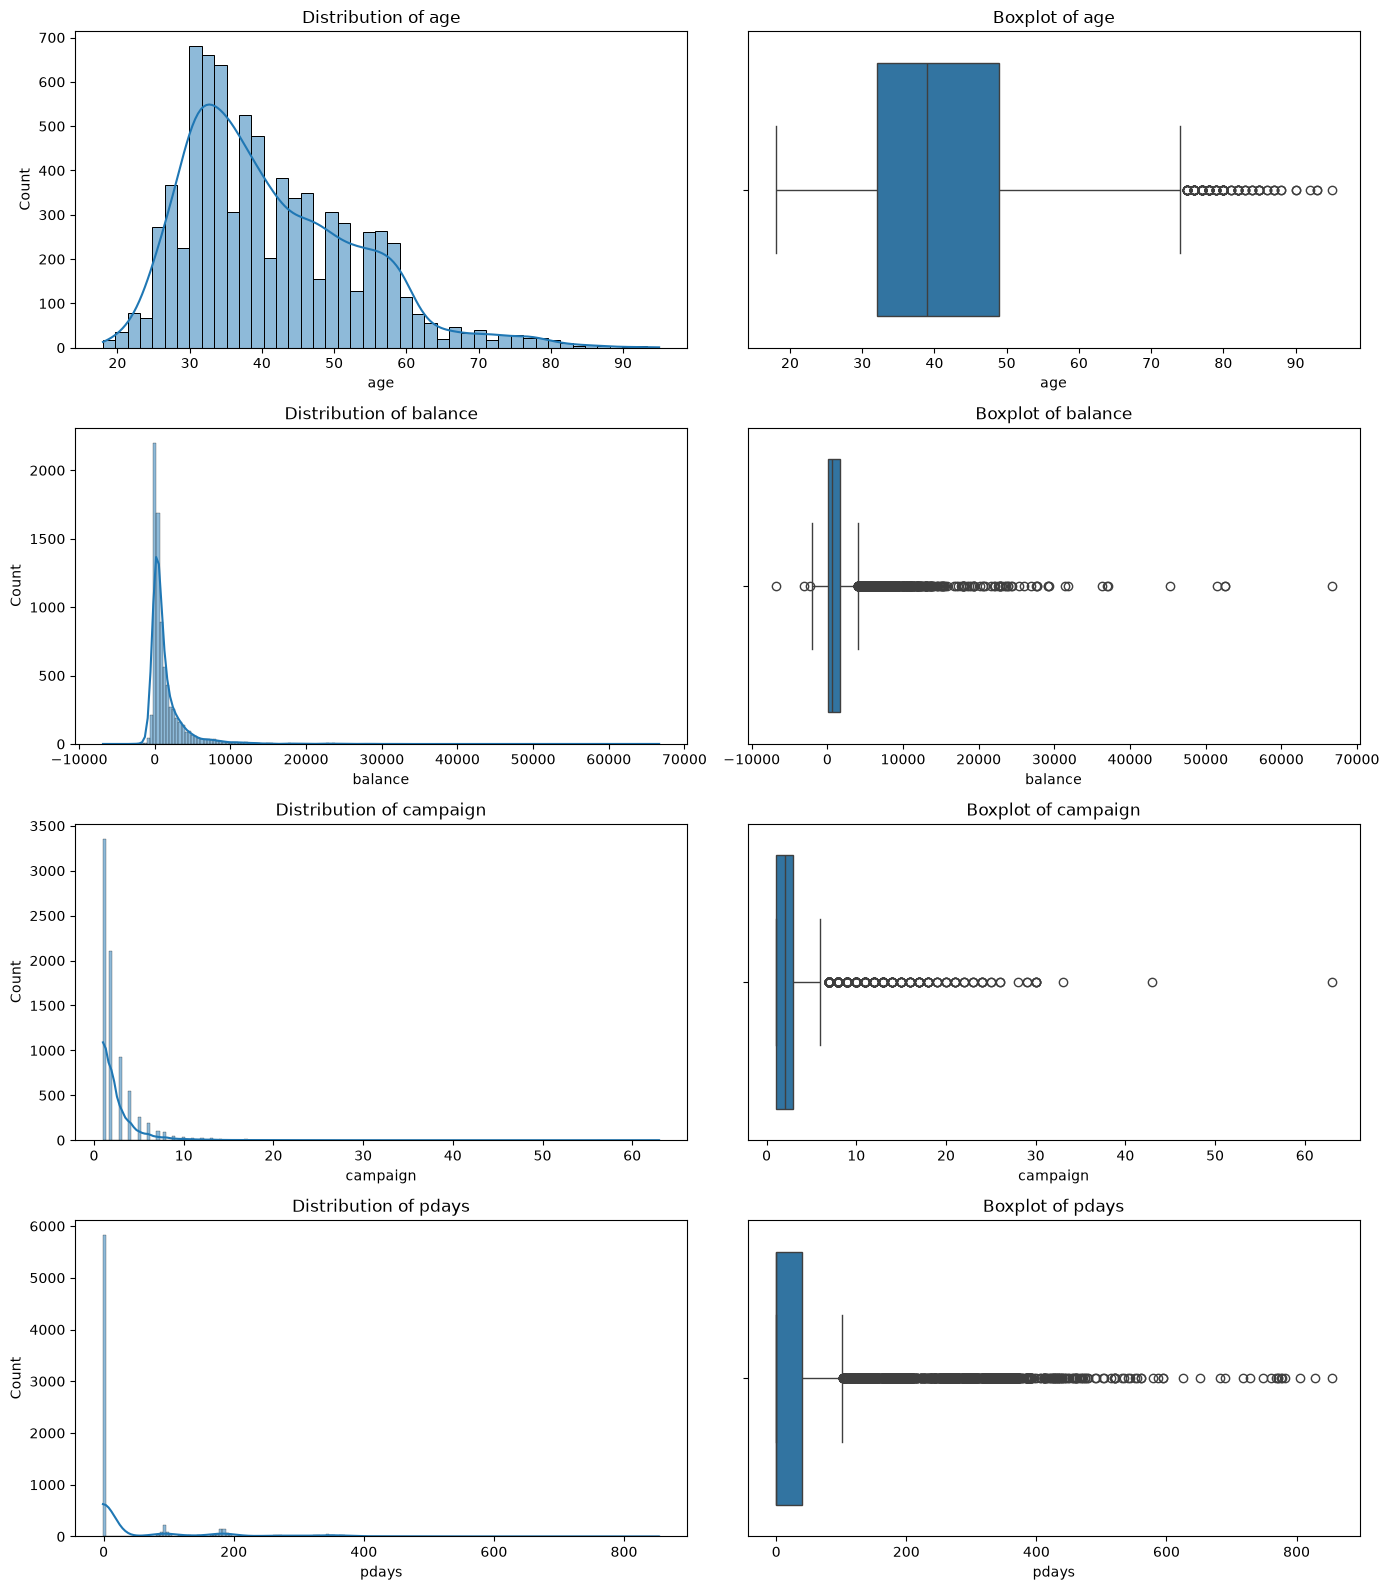

In [10]:
# visualisasi num_feature
ig, axes = plt.subplots(
    len(num_features), 2,
    figsize=(14, 4 * len(num_features))
)

for i, col in enumerate(num_features):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f'Distribution of {col}')

    sns.boxplot(data=df, x=col, ax=axes[i, 1])
    axes[i, 1].set_title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

**Analisis khusus setiap fitur numerik**

In [11]:
# age
print("Age Distribution:")
print(df['age'].describe())

print("\nAge Frequency:")
print(df['age'].value_counts(
    bins=5, sort=False
))

Age Distribution:
count    7813.000000
mean       41.257264
std        11.919710
min        18.000000
25%        32.000000
50%        39.000000
75%        49.000000
max        95.000000
Name: age, dtype: float64

Age Frequency:
(17.921999999999997, 33.4]    2403
(33.4, 48.8]                  3377
(48.8, 64.2]                  1726
(64.2, 79.6]                   259
(79.6, 95.0]                    48
Name: count, dtype: int64


In [12]:
# balance
print("Balance Statistics:")
print(df['balance'].describe())

print("\nNegative Balance:")
print(f"Count: {(df['balance'] < 0).sum()}")
print(f"Percentage: {(df['balance'] < 0).mean() * 100:.2f}%")

print("\nZero Balance:")
print(f"Count: {(df['balance'] == 0).sum()}")

Balance Statistics:
count     7813.000000
mean      1512.448611
std       3089.291831
min      -6847.000000
25%        127.000000
50%        549.000000
75%       1684.000000
max      66653.000000
Name: balance, dtype: float64

Negative Balance:
Count: 479
Percentage: 6.13%

Zero Balance:
Count: 546


In [13]:
# campaign
print("Campaign Frequency:")
print(df['campaign'].value_counts().sort_index())

print("\nCampaign Percentage:")
print(
    df['campaign'].value_counts(
        normalize=True
    ).sort_index() * 100
)

Campaign Frequency:
campaign
1     3354
2     2108
3      922
4      548
5      256
6      196
7      103
8       89
9       47
10      41
11      28
12      20
13      23
14      10
15       8
16       7
17       9
18       7
19       4
20       4
21       5
22       3
23       3
24       4
25       2
26       2
28       1
29       2
30       4
33       1
43       1
63       1
Name: count, dtype: int64

Campaign Percentage:
campaign
1     42.928453
2     26.980673
3     11.800845
4      7.013951
5      3.276590
6      2.508639
7      1.318316
8      1.139127
9      0.601562
10     0.524766
11     0.358377
12     0.255984
13     0.294381
14     0.127992
15     0.102393
16     0.089594
17     0.115193
18     0.089594
19     0.051197
20     0.051197
21     0.063996
22     0.038398
23     0.038398
24     0.051197
25     0.025598
26     0.025598
28     0.012799
29     0.025598
30     0.051197
33     0.012799
43     0.012799
63     0.012799
Name: proportion, dtype: float64


In [14]:
# pdays
print("Pdays Frequency:")
print(df['pdays'].value_counts().sort_index())

print("\nPdays Percentage:")
print(
    df['pdays'].value_counts(
        normalize=True
    ).sort_index() * 100
)

Pdays Frequency:
pdays
-1      5817
 1         3
 2         4
 4         1
 5         1
        ... 
 778       1
 782       1
 805       1
 828       1
 854       1
Name: count, Length: 422, dtype: int64

Pdays Percentage:
pdays
-1      74.452835
 1       0.038398
 2       0.051197
 4       0.012799
 5       0.012799
          ...    
 778     0.012799
 782     0.012799
 805     0.012799
 828     0.012799
 854     0.012799
Name: proportion, Length: 422, dtype: float64


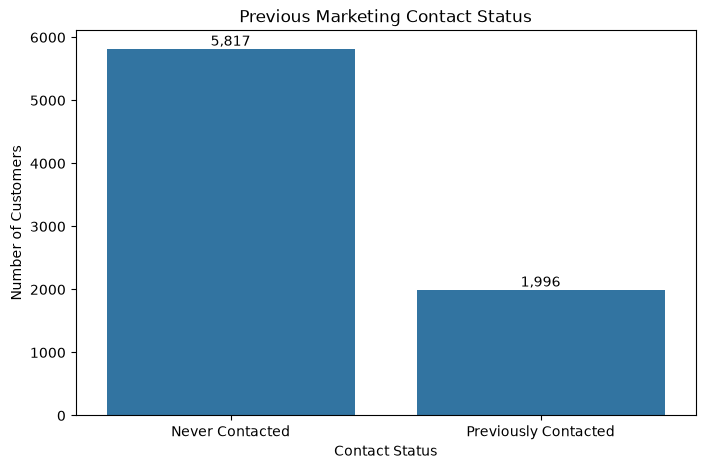

In [15]:
# pdays status with and without previous contact
pdays_status = pd.Series({
    'Never Contacted': (df['pdays'] == -1).sum(),
    'Previously Contacted': (df['pdays'] != -1).sum()
})

plt.figure(figsize=(8, 5))

sns.barplot(
    x=pdays_status.index,
    y=pdays_status.values
)

plt.title('Previous Marketing Contact Status')
plt.xlabel('Contact Status')
plt.ylabel('Number of Customers')

for i, value in enumerate(pdays_status.values):
    plt.text(i, value + 50, f'{value:,}', ha='center')

plt.show()

**OVERALL INSIGHT — NUMERICAL FEATURES**

Univariate analysis dilakukan untuk memahami karakteristik dan distribusi masing-masing fitur numerik dalam dataset. Analisis ini menggunakan histogram untuk mengamati bentuk distribusi data serta boxplot untuk mengidentifikasi persebaran nilai dan indikasi pencilan.

**1. Kolom `age`**

Berdasarkan histogram, distribusi usia nasabah terkonsentrasi pada rentang sekitar 30–50 tahun, dengan frekuensi tertinggi berada pada rentang usia 30–35 tahun. Distribusi cenderung right-skewed, yang ditunjukkan oleh ekor distribusi yang memanjang ke arah usia lebih tua. Boxplot juga menunjukkan beberapa indikasi pencilan pada usia di atas sekitar 74 tahun.

Hal ini menunjukkan bahwa mayoritas nasabah dalam dataset berada pada kelompok usia produktif, meskipun terdapat sebagian kecil nasabah dengan usia yang lebih tinggi.

**2. Kolom `balance`**

Distribusi saldo nasabah menunjukkan pola highly right-skewed, dengan sebagian besar nilai terkonsentrasi pada rentang saldo yang relatif rendah. Selain itu, ditemukan nilai saldo negatif serta sejumlah nilai ekstrem pada sisi kanan distribusi.

Hal ini menunjukkan adanya variasi saldo yang cukup besar antar nasabah. Nilai ekstrem tersebut perlu diperiksa lebih lanjut untuk memastikan apakah mencerminkan kondisi saldo yang valid atau kesalahan pencatatan.

**3. Kolom `campaign`**

Distribusi jumlah kontak selama campaign menunjukkan pola highly right-skewed. Sebagian besar nasabah dihubungi sebanyak 1–3 kali, sedangkan sebagian kecil nasabah menerima kontak dalam jumlah yang jauh lebih besar. Boxplot juga menunjukkan adanya sejumlah indikasi pencilan, dengan nilai maksimum mencapai 63 kali kontak.

Hal ini menggambarkan bahwa intensitas aktivitas pemasaran berbeda-beda antar nasabah.

**4. Kolom `pdays`**

Distribusi fitur pdays menunjukkan konsentrasi yang sangat besar pada nilai -1, yaitu sebanyak 5.817 data atau sekitar 74,45% dari keseluruhan observasi. Nilai tersebut menunjukkan bahwa sebagian besar nasabah belum pernah dihubungi dalam campaign sebelumnya.

Sementara itu, nasabah yang pernah dihubungi sebelumnya memiliki variasi rentang waktu kontak yang cukup besar, dengan distribusi yang cenderung right-skewed dan sejumlah indikasi pencilan.

**Overall Insight**

Secara keseluruhan, fitur numerik dalam dataset memiliki distribusi yang cenderung right-skewed, khususnya balance, campaign, dan pdays. Selain itu, ditemukan sejumlah nilai ekstrem pada beberapa fitur yang perlu dianalisis lebih lanjut sebelum menentukan metode preprocessing.

Temuan ini menjadi dasar untuk menentukan strategi penanganan pencilan, transformasi data, dan fitur engineering pada tahap selanjutnya.

Selanjutnya, identifikasi catecorigal fiturs

In [16]:
# identifikasi categorical features
cat_features = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

cat_features.remove("deposit")
print("Categorical Features: ")
print(cat_features)

Categorical Features: 
['job', 'housing', 'loan', 'contact', 'month', 'poutcome']


C:\Users\HP\AppData\Local\Temp\ipykernel_8640\535954525.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = df.select_dtypes(


Selanjutnya, akan divisualisasikan untuk cat_fiturs

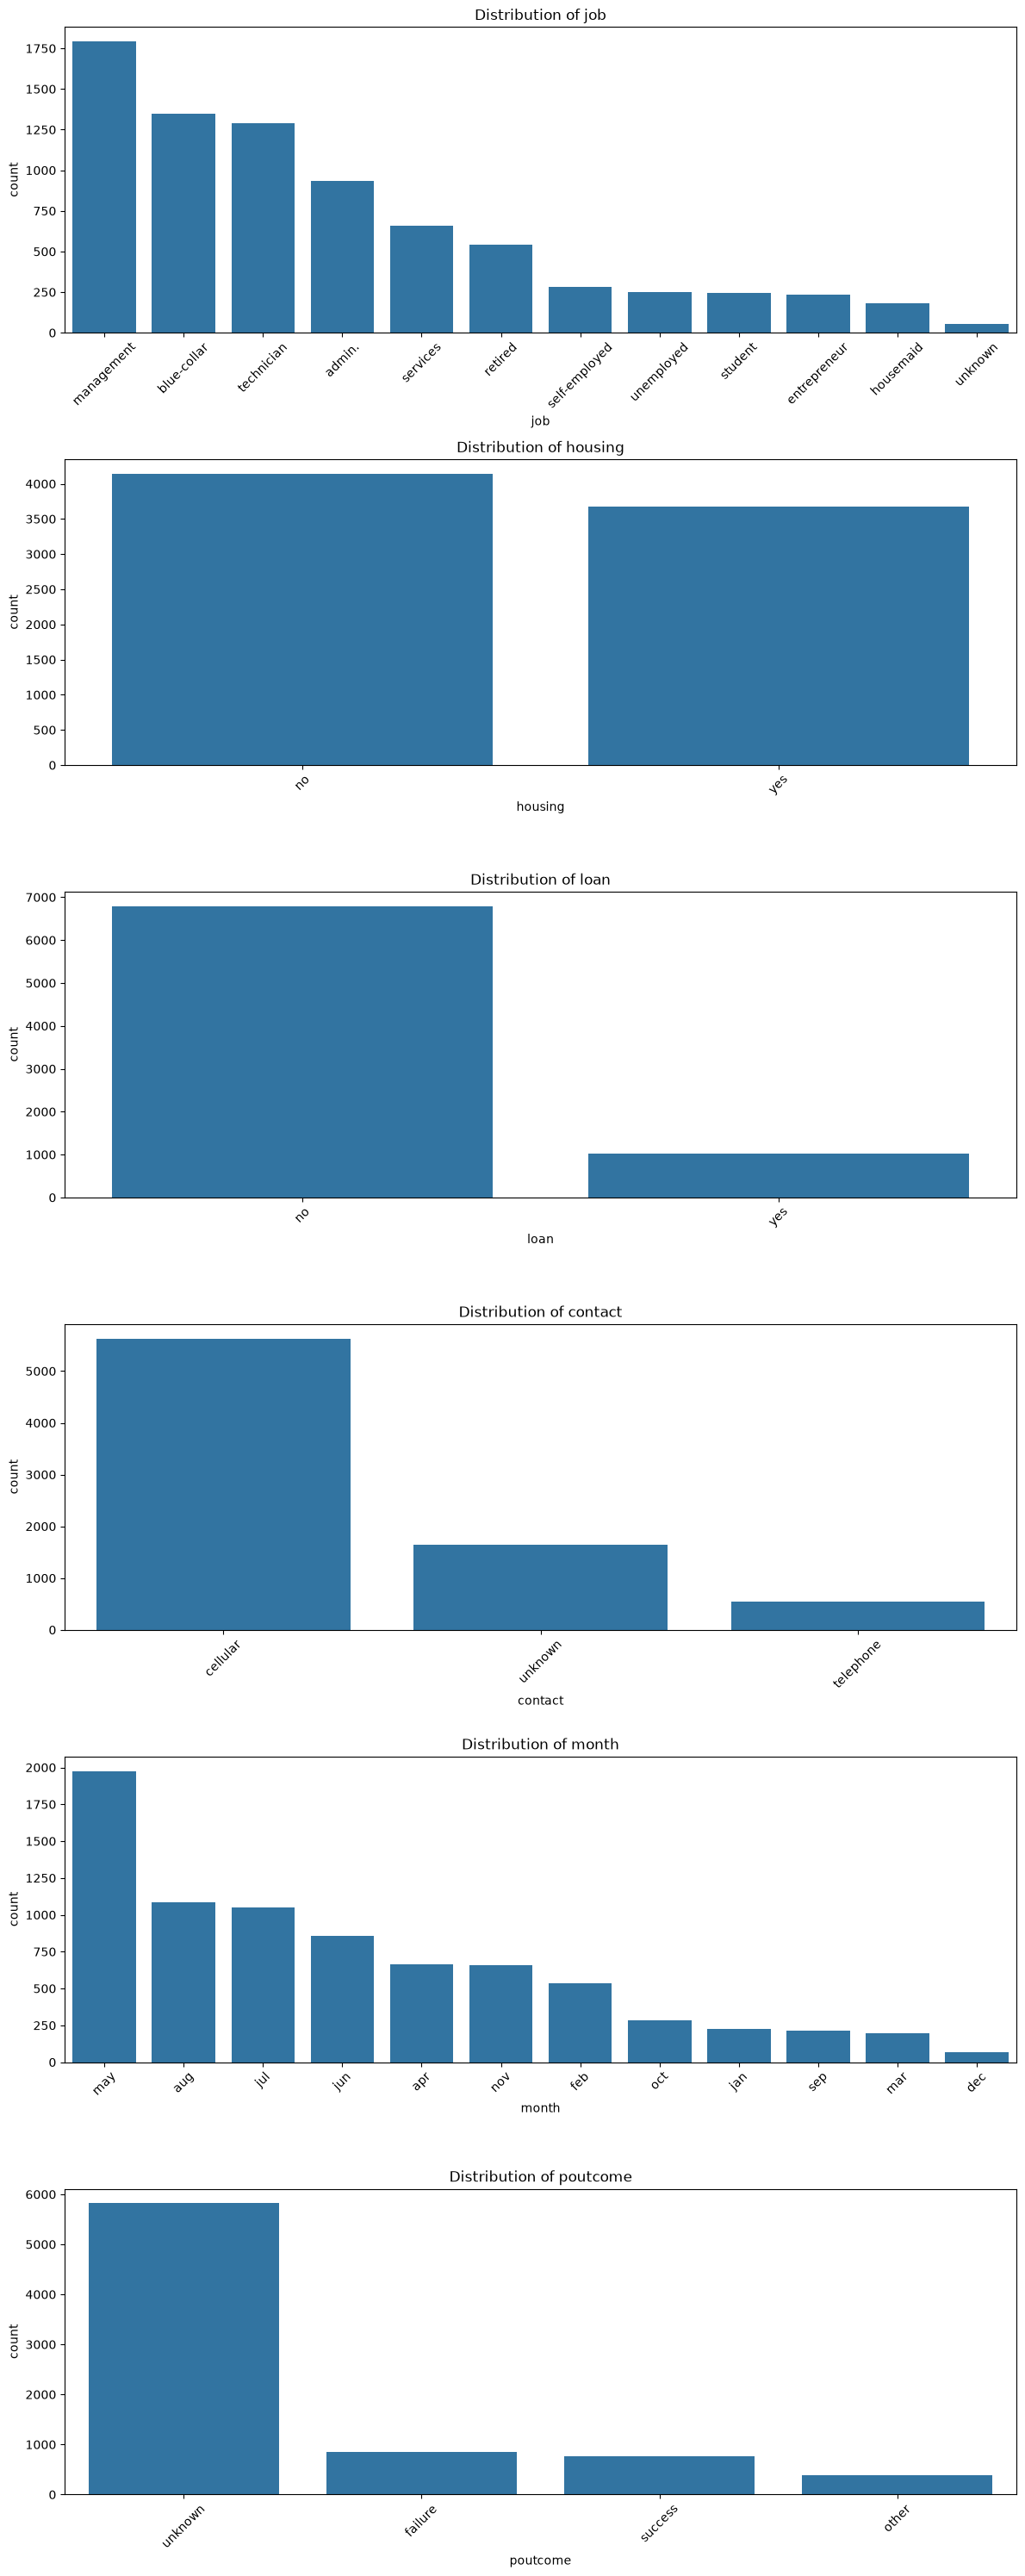

In [17]:
# Visualisasi categorical features
fig, axes = plt.subplots(
    len(cat_features), 1,
    figsize=(12, 5 * len(cat_features))
)

for i, col in enumerate(cat_features):
    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index,
        ax=axes[i]
    )

    axes[i].set_title(f'Distribution of {col}')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Selanjutnya, akan dilihat untuk spesifik distribusi kelas deposit

In [18]:
# Menghitung jumlah setiap kelas
print(df["deposit"].value_counts())

# Menghitung persentase setiap kelas
print(df["deposit"].value_counts(normalize=True)*100)

deposit
no     4081
yes    3732
Name: count, dtype: int64
deposit
no     52.233457
yes    47.766543
Name: proportion, dtype: float64


Untuk visualisasinya:

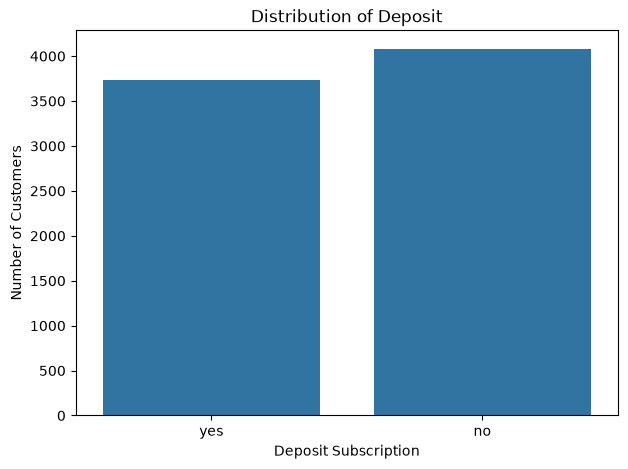

In [19]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='deposit')

plt.title('Distribution of Deposit')
plt.xlabel('Deposit Subscription')
plt.ylabel('Number of Customers')

plt.show()

### **OVERALL INSIGHT — CATEGORICAL FEATURES**

Berdasarkan hasil analisis terhadap fitur kategorik, ditemukan bahwa distribusi kategori pada setiap fitur memiliki karakteristik yang berbeda-beda.

Pada fitur `job`, nasabah didominasi oleh kelompok pekerjaan management, blue-collar, dan technician. Sementara itu, fitur `housing` menunjukkan distribusi yang relatif seimbang antara nasabah yang memiliki dan tidak memiliki pinjaman perumahan. Berbeda dengan fitur `loan`, yang didominasi oleh nasabah tanpa pinjaman pribadi.

Pada fitur `contact`, komunikasi melalui cellular menjadi metode yang paling banyak digunakan. Sementara itu, aktivitas marketing campaign berdasarkan fitur `month` terkonsentrasi pada bulan May, August, dan July.

Selain itu, ditemukan bahwa fitur `poutcome` memiliki proporsi kategori unknown yang cukup besar, yaitu 74,48%. Hal ini menunjukkan bahwa informasi hasil campaign sebelumnya tidak diketahui atau tidak tersedia pada sebagian besar observasi.

Terakhir, distribusi target variable `deposit` menunjukkan proporsi yang relatif seimbang antara nasabah yang tidak melakukan deposito (52,23%) dan nasabah yang melakukan deposito (47,77%). Dengan demikian, dataset tidak menunjukkan indikasi ketimpangan kelas yang ekstrem.

Temuan dari analisis ini akan menjadi dasar dalam menentukan strategi preprocessing, encoding, dan fitur engineering pada tahap selanjutnya.

Selanjutnya, akan dilakukan Bivariate Analysis untuk melihat hubungan antara num_featurs dan cat_featurs dengan target variabel yaitu `deposit`

**1. Numerical Features vs Target** 

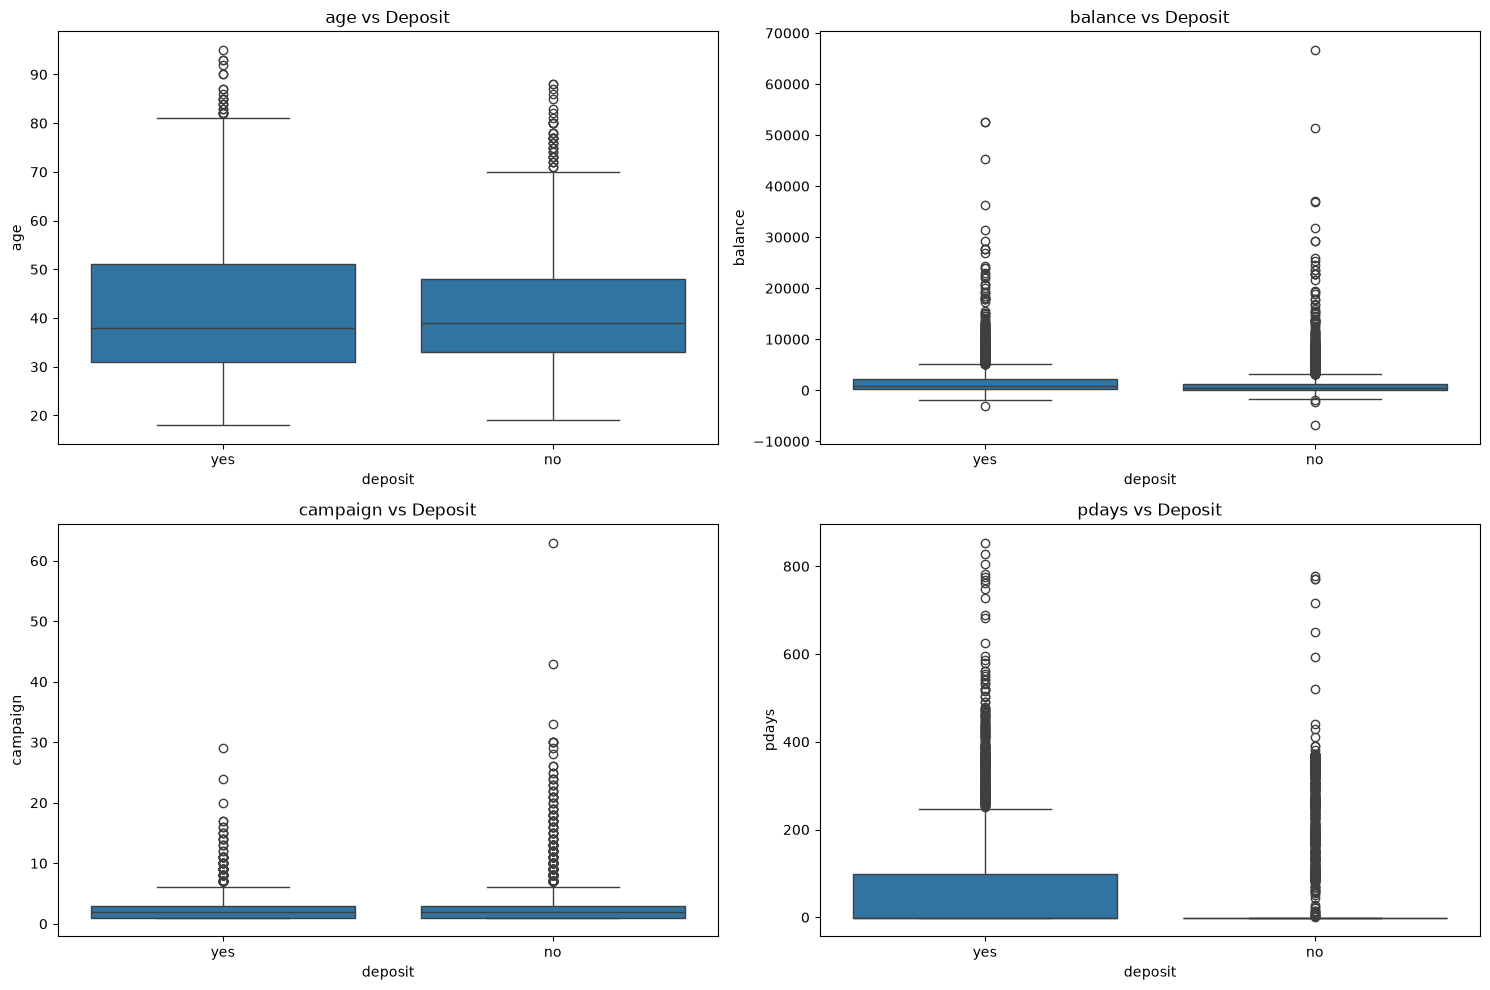

In [20]:
# visualisasi hubungan num_features dengan deposit menggunakan boxplot
fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 10)
)

axes = axes.flatten()

for i, col in enumerate(num_features):
    sns.boxplot(
        data=df,
        x='deposit',
        y=col,
        ax=axes[i]
    )

    axes[i].set_title(f'{col} vs Deposit')

plt.tight_layout()
plt.show()

**2. Categorical Features vs Target**

In [21]:
# Crosstabulation untuk kolom cat_features
for col in cat_features:

    print(f"\n{'='*40}")
    print(f"Feature: {col}")
    print(f"{'='*40}")

    result = pd.crosstab(
        df[col],
        df['deposit'],
        margins=True
    )

    print(result)


Feature: job
deposit          no   yes   All
job                            
admin.          492   444   936
blue-collar     842   504  1346
entrepreneur    142    94   236
housemaid       112    72   184
management      878   914  1792
retired         175   365   540
self-employed   153   127   280
services        398   260   658
student          63   184   247
technician      696   595  1291
unemployed      102   147   249
unknown          28    26    54
All            4081  3732  7813

Feature: housing
deposit    no   yes   All
housing                  
no       1751  2389  4140
yes      2330  1343  3673
All      4081  3732  7813

Feature: loan
deposit    no   yes   All
loan                     
no       3387  3402  6789
yes       694   330  1024
All      4081  3732  7813

Feature: contact
deposit      no   yes   All
contact                    
cellular   2528  3100  5628
telephone   276   270   546
unknown    1277   362  1639
All        4081  3732  7813

Feature: month
deposit    

In [22]:
# deposit convertion rate
for col in cat_features:

    print(f"\n{'='*40}")
    print(f"Deposit Rate by {col}")
    print(f"{'='*40}")

    deposit_rate = (
        df.groupby(col)['deposit']
        .apply(lambda x: (x == 'yes').mean() * 100)
        .sort_values(ascending=False)
    )

    print(deposit_rate.round(2))


Deposit Rate by job
job
student          74.49
retired          67.59
unemployed       59.04
management       51.00
unknown          48.15
admin.           47.44
technician       46.09
self-employed    45.36
entrepreneur     39.83
services         39.51
housemaid        39.13
blue-collar      37.44
Name: deposit, dtype: float64

Deposit Rate by housing
housing
no     57.71
yes    36.56
Name: deposit, dtype: float64

Deposit Rate by loan
loan
no     50.11
yes    32.23
Name: deposit, dtype: float64

Deposit Rate by contact
contact
cellular     55.08
telephone    49.45
unknown      22.09
Name: deposit, dtype: float64

Deposit Rate by month
month
mar    88.94
dec    88.24
oct    84.97
sep    83.96
apr    62.69
feb    56.37
aug    45.71
jun    44.92
nov    44.14
jan    43.61
jul    40.86
may    33.35
Name: deposit, dtype: float64

Deposit Rate by poutcome
poutcome
success    91.46
other      58.70
failure    51.30
unknown    40.81
Name: deposit, dtype: float64


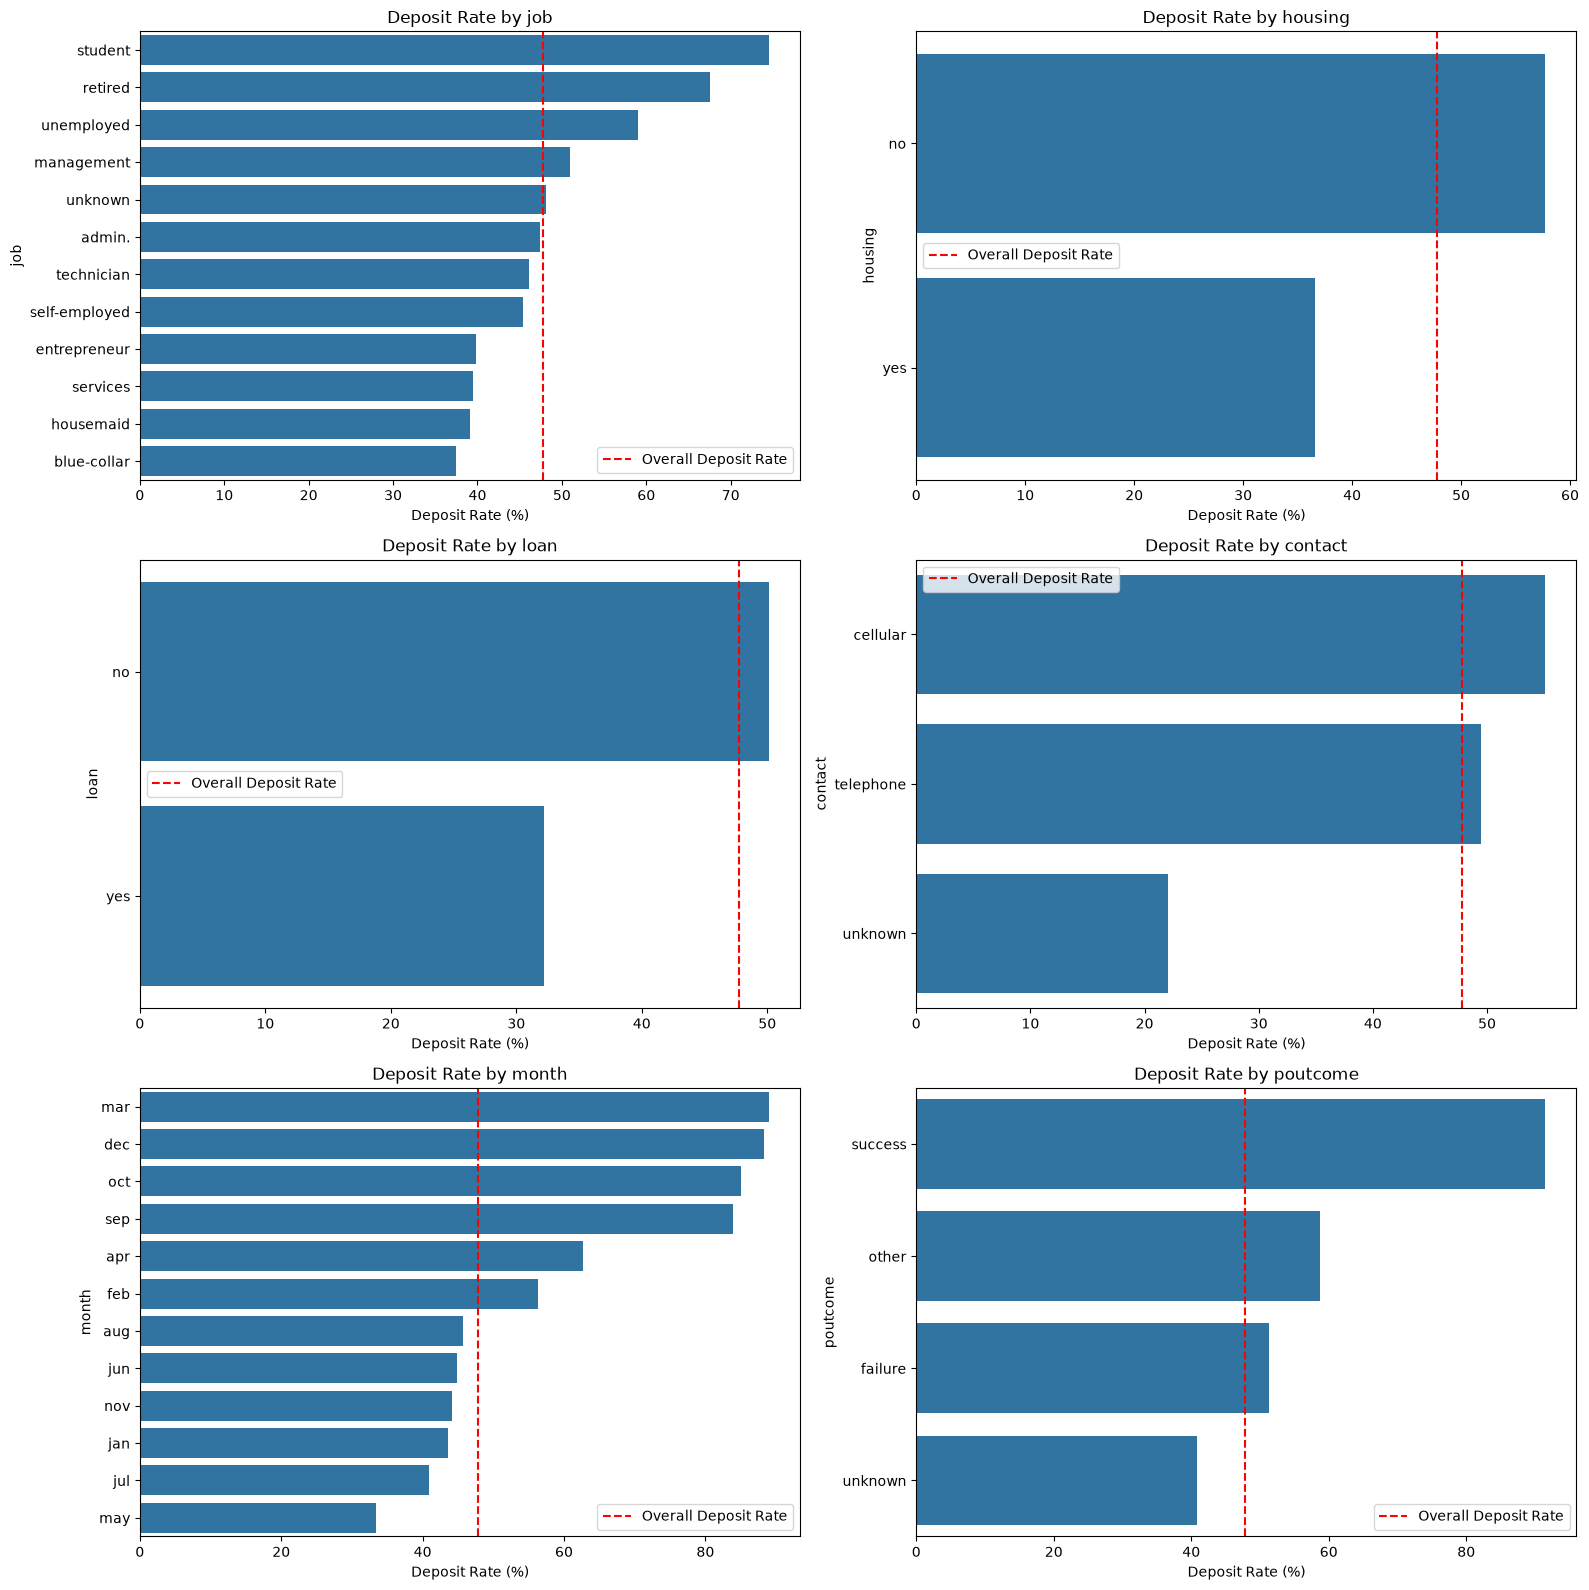

In [23]:
# visualisasi deposito convertion rate
fig, axes = plt.subplots(
    3, 2,
    figsize=(16, 16)
)

axes = axes.flatten()

for i, col in enumerate(cat_features):

    rate = (
        df.groupby(col)['deposit']
        .apply(lambda x: (x == 'yes').mean() * 100)
        .sort_values(ascending=False)
    )

    sns.barplot(
        x=rate.values,
        y=rate.index,
        ax=axes[i]
    )

    axes[i].set_title(f'Deposit Rate by {col}')
    axes[i].set_xlabel('Deposit Rate (%)')
    axes[i].set_ylabel(col)

    axes[i].axvline(
        (df['deposit'] == 'yes').mean() * 100,
        linestyle='--',
        color='red',
        label='Overall Deposit Rate'
    )

    axes[i].legend()

plt.tight_layout()
plt.show()

**3. Analisis Korelasi**

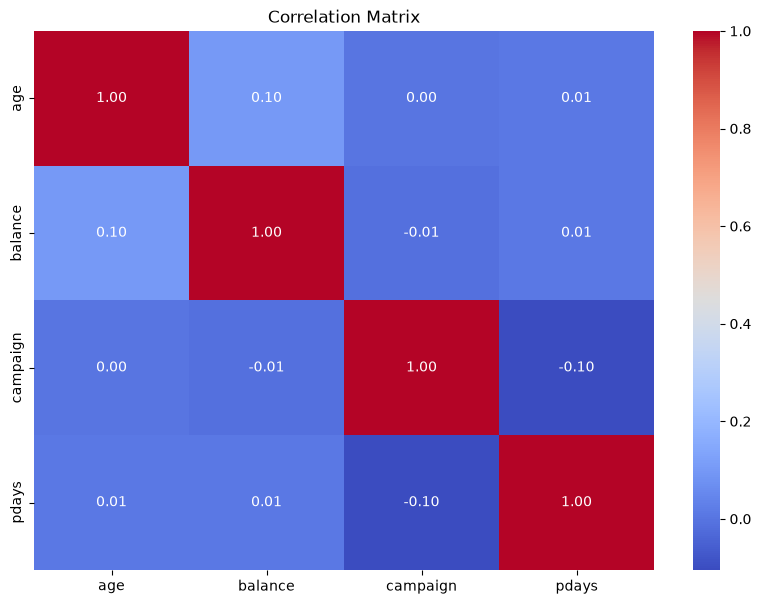

In [24]:
plt.figure(figsize=(10, 7))

corr = df[num_features].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')
plt.show()

### **EDA SUMMARY & KEY FINDINGS**

Berdasarkan hasil Exploratory Data Analysis (EDA) yang telah dilakukan, diperoleh beberapa temuan penting mengenai karakteristik dataset Bank Marketing Campaign serta pola hubungan antara fitur-fitur yang tersedia dengan keputusan nasabah dalam melakukan deposito berjangka.

**1. Karakteristik Numerical Features**

Sebagian besar fitur numerik menunjukkan distribusi yang cenderung right-skewed, khususnya pada fitur `balance`, `campaign`, dan `pdays`. Selain itu, ditemukan sejumlah nilai ekstrem pada beberapa fitur yang perlu dievaluasi lebih lanjut sebelum menentukan metode penanganannya.

Pada fitur `pdays`, ditemukan bahwa sebanyak 74,45% observasi memiliki nilai -1, yang merepresentasikan nasabah yang belum pernah dihubungi dalam campaign sebelumnya. Oleh karena itu, nilai tersebut perlu dipertahankan sebagai informasi khusus dan tidak diperlakukan sebagai nilai numerik biasa.

**2. Karakteristik Categorical Features**

Hasil analisis menunjukkan bahwa beberapa kategori memiliki distribusi yang tidak merata. Pada fitur `job`, nasabah didominasi oleh kelompok management, blue-collar, dan technician. Sementara itu, fitur `poutcome` memiliki proporsi kategori unknown sebesar 74,48%.

Temuan tersebut menunjukkan bahwa terdapat beberapa informasi kategorikal yang tidak diketahui atau tidak tersedia pada sebagian besar observasi. Penanganan kategori tersebut perlu mempertimbangkan makna bisnis dan kontribusinya terhadap prediksi.

**3. Hubungan Features dengan Target Variable**

Berdasarkan analisis hubungan antara fitur dengan target `deposit`, ditemukan beberapa perbedaan karakteristik antara nasabah yang melakukan dan tidak melakukan deposito.

Pada fitur numerik, terdapat perbedaan distribusi antara kedua kelompok, meskipun beberapa fitur masih menunjukkan persebaran yang saling tumpang tindih.

Sementara itu, pada fitur kategorikal, ditemukan bahwa:
- Kategori pekerjaan student memiliki deposit rate tertinggi sebesar 74,49%.
- Nasabah tanpa housing loan memiliki deposit rate sebesar 57,71%, lebih tinggi dibandingkan nasabah dengan housing loan.
- Nasabah tanpa personal loan memiliki deposit rate sebesar 50,11%.
- Metode komunikasi cellular memiliki deposit rate sebesar 55,08%.
- Bulan March memiliki deposit rate tertinggi sebesar 88,94%.
- Kategori poutcome success memiliki deposit rate sebesar 91,46%.

Temuan tersebut menunjukkan bahwa terdapat perbedaan tingkat keberhasilan deposito berdasarkan karakteristik nasabah dan riwayat aktivitas pemasaran. Namun, hubungan tersebut belum menunjukkan hubungan sebab-akibat dan perlu dievaluasi lebih lanjut melalui pemodelan.

**4. Correlation Analysis**

Berdasarkan correlation matrix, seluruh pasangan fitur numerik menunjukkan korelasi linear yang relatif lemah. Korelasi tertinggi ditemukan antara `age` dan `balance` sebesar 0,10, sedangkan korelasi terendah ditemukan antara `campaign` dan `pdays` sebesar -0,10.

Hal ini menunjukkan bahwa belum ditemukan hubungan linear yang kuat antar fitur numerik dalam dataset.

**5. Target Variable Distribution**

Distribusi target variable `deposit` menunjukkan bahwa sebanyak 52,23% nasabah tidak melakukan deposito, sedangkan 47,77% nasabah melakukan deposito.

Dengan demikian, dataset tidak menunjukkan indikasi class imbalance yang ekstrem sehingga proses pemodelan dapat dimulai menggunakan distribusi data asli tanpa harus langsung menerapkan teknik oversampling maupun undersampling.

## **4. DATA QUALITY ASSESSMENT**

In [25]:
df_clean = df.copy()

**A. MISSING VALUES**

In [26]:
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (
        df.isnull().mean() * 100
    ).round(2)
})

display(missing_summary)

,Missing Count,Missing Percentage
age,0,0.0
job,0,0.0
balance,0,0.0
housing,0,0.0
loan,0,0.0
contact,0,0.0
month,0,0.0
campaign,0,0.0
pdays,0,0.0
poutcome,0,0.0


Berdasarkan hasil pemeriksaan nilai kosong, tidak ditemukan nilai kosong pada seluruh kolom dataset. Setiap fitur memiliki jumlah nilai kosong sebesar 0 atau 0% dari keseluruhan observasi.

Dengan demikian, tidak diperlukan proses imputasi maupun penghapusan data berdasarkan nilai kosong.



**B. DUPLICATED ROWS**

In [27]:
# Duplicate Records Analysis

print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 8


Berdasarkan hasil pemeriksaan data duplikat, ditemukan sebanyak 8 baris yang memiliki nilai identik pada seluruh kolom dataset.

In [28]:
# Display duplicated records

duplicated_rows = df_clean[
    df_clean.duplicated(keep=False)
]

display(duplicated_rows.sort_values(
    by=df_clean.columns.tolist()
))

,age,job,balance,housing,loan,contact,month,campaign,pdays,poutcome,deposit
2486,30,blue-collar,239,yes,no,unknown,may,1,-1,unknown,yes
7077,30,blue-collar,239,yes,no,unknown,may,1,-1,unknown,yes
1468,34,management,0,no,no,cellular,aug,2,-1,unknown,no
5905,34,management,0,no,no,cellular,aug,2,-1,unknown,no
223,38,technician,0,no,no,cellular,aug,2,-1,unknown,no
5681,38,technician,0,no,no,cellular,aug,2,-1,unknown,no
1381,39,technician,0,yes,no,unknown,may,1,-1,unknown,no
5609,39,technician,0,yes,no,unknown,may,1,-1,unknown,no
330,40,blue-collar,0,yes,no,unknown,may,2,-1,unknown,no
2944,40,blue-collar,0,yes,no,unknown,may,2,-1,unknown,no


In [29]:
# Remove duplicate records

df_clean = df_clean.drop_duplicates()

# Verify duplicate records
print(
    "Duplicate Rows After Cleaning:",
    df_clean.duplicated().sum()
)

# Check dataset dimensions
print("Dataset Shape:", df_clean.shape)

Duplicate Rows After Cleaning: 0
Dataset Shape: (7805, 11)


**Duplicate Records Handling**

Berdasarkan pemeriksaan terhadap seluruh kolom dataset, ditemukan sebanyak 8 baris duplikat. Setelah dilakukan pemeriksaan lebih lanjut menggunakan keep=False, ditemukan 8 pasang baris yang memiliki nilai identik pada seluruh atribut.

Karena baris-baris tersebut tidak memberikan informasi tambahan yang berbeda, dilakukan penghapusan terhadap data duplikat dengan mempertahankan satu observasi dari setiap kelompok duplikasi.

Penghapusan dilakukan menggunakan fungsi drop_duplicates(). Setelah proses tersebut, dilakukan pemeriksaan ulang untuk memastikan tidak terdapat lagi data duplikat pada dataset.

**C. UNIQUE VALUES**

In [30]:
# Unique Values Analysis

for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

age: 75 unique values
job: 12 unique values
balance: 3153 unique values
housing: 2 unique values
loan: 2 unique values
contact: 3 unique values
month: 12 unique values
campaign: 32 unique values
pdays: 422 unique values
poutcome: 4 unique values
deposit: 2 unique values


In [31]:
# Categorical Unique Values Inspection

for col in cat_features:
    print(f"\n{'='*40}")
    print(f"Feature: {col}")
    print(f"{'='*40}")

    print(df_clean[col].value_counts(dropna=False))


Feature: job
job
management       1789
blue-collar      1343
technician       1289
admin.            936
services          658
retired           540
self-employed     280
unemployed        249
student           247
entrepreneur      236
housemaid         184
unknown            54
Name: count, dtype: int64

Feature: housing
housing
no     4136
yes    3669
Name: count, dtype: int64

Feature: loan
loan
no     6781
yes    1024
Name: count, dtype: int64

Feature: contact
contact
cellular     5623
unknown      1636
telephone     546
Name: count, dtype: int64

Feature: month
month
may    1973
aug    1081
jul    1049
jun     857
apr     662
nov     657
feb     534
oct     286
jan     227
sep     212
mar     199
dec      68
Name: count, dtype: int64

Feature: poutcome
poutcome
unknown    5811
failure     848
success     761
other       385
Name: count, dtype: int64


**Categorical Values Inspection**

Berdasarkan pemeriksaan terhadap unique values dan frekuensi kemunculan setiap kategori, ditemukan bahwa seluruh fitur kategorik memiliki variasi kategori yang sesuai dengan karakteristik atributnya.

Pada fitur `job`, ditemukan 12 kategori pekerjaan dengan kategori management sebagai kelompok terbanyak. Selain itu, terdapat kategori unknown sebanyak 54 observasi.

Pada fitur `housing` dan `loan`, masing-masing hanya memiliki dua kategori, yaitu yes dan no. Sementara itu, fitur `contact` memiliki tiga kategori, yaitu cellular, telephone, dan unknown.

Pada fitur `month`, seluruh 12 bulan ditemukan dalam dataset. Adapun fitur `poutcome` memiliki empat kategori, yaitu unknown, failure, success, dan other, dengan kategori unknown sebagai kategori yang paling dominan.

Meskipun terdapat kategori unknown pada beberapa fitur, kategori tersebut tidak langsung dianggap sebagai kesalahan data karena dapat merepresentasikan informasi yang tidak tersedia.

Dengan demikian, seluruh kategori yang ditemukan dipertahankan karena belum terdapat bukti yang menunjukkan adanya kategori tidak valid atau inkonsistensi penulisan yang memerlukan perubahan.

In [32]:
# Numerical Unique Values Inspection

for col in num_features:
    print(f"\n{'='*40}")
    print(f"Feature: {col}")
    print(f"{'='*40}")

    print("Minimum:", df_clean[col].min())
    print("Maximum:", df_clean[col].max())
    print("Unique Values:", df_clean[col].nunique())


Feature: age
Minimum: 18
Maximum: 95
Unique Values: 75

Feature: balance
Minimum: -6847
Maximum: 66653
Unique Values: 3153

Feature: campaign
Minimum: 1
Maximum: 63
Unique Values: 32

Feature: pdays
Minimum: -1
Maximum: 854
Unique Values: 422


**Numerical Values Validation**

Berdasarkan pemeriksaan terhadap fitur numerik, diperoleh rentang nilai yang bervariasi pada setiap atribut.

Pada fitur `age`, ditemukan rentang usia antara 18 hingga 95 tahun. Rentang tersebut masih tergolong masuk akal sehingga tidak diperlukan perubahan terhadap nilai usia.

Pada fitur `balance`, ditemukan nilai minimum sebesar -6.847 dan maksimum sebesar 66.653. Nilai saldo negatif tidak langsung dianggap sebagai kesalahan data karena dapat merepresentasikan kondisi rekening nasabah. Sementara itu, nilai saldo yang ekstrem perlu dievaluasi lebih lanjut.

Pada fitur `campaign`, ditemukan jumlah kontak minimum sebanyak 1 kali dan maksimum sebanyak 63 kali. Meskipun tidak ditemukan nilai nol atau negatif, nilai maksimum menunjukkan adanya observasi dengan jumlah kontak yang cukup tinggi.

Selanjutnya, fitur `pdays` memiliki nilai minimum -1 dan maksimum 854. Nilai -1 merupakan nilai khusus yang menunjukkan bahwa nasabah belum pernah dihubungi dalam campaign sebelumnya. Oleh karena itu, nilai tersebut tetap dipertahankan dan tidak dianggap sebagai missing value.

Secara keseluruhan, belum ditemukan nilai numerik yang dapat dipastikan tidak valid berdasarkan pemeriksaan rentang nilai. Penanganan terhadap nilai ekstrem akan dievaluasi lebih lanjut melalui analisis pencilan sebelum menentukan metode treatment yang sesuai.

**D. Outlier Assesment**

In [33]:
# Outlier Detection using IQR

outlier_summary = []

for col in num_features:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]

    outlier_summary.append({
        'Feature': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage': (
            len(outliers) / len(df_clean) * 100
        )
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df.round(2))

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,age,6.5,74.5,121,1.55
1,balance,-2207.5,4020.5,736,9.43
2,campaign,-2.0,6.0,429,5.50
3,pdays,-64.0,104.0,1432,18.35


**Outlier Detection & Evaluation**

Deteksi pencilan dilakukan menggunakan metode Interquartile Range (IQR) untuk mengidentifikasi observasi yang berada di luar batas distribusi normal berdasarkan kuartil pertama dan kuartil ketiga.

Berdasarkan hasil pemeriksaan, ditemukan pencilan pada seluruh fitur numerik, dengan rincian sebagai berikut:

- `age`: 121 observasi (1,55%).
- `balance`: 736 observasi (9,43%).
- `campaign`: 429 observasi (5,50%).
- `pdays`: 1.432 observasi (18,35%).

Pada fitur `age`, nilai yang teridentifikasi sebagai pencilan merupakan usia di atas 74,5 tahun. Nilai tersebut masih dianggap valid karena nasabah berusia lanjut tetap memungkinkan untuk melakukan deposito.

Pada fitur `balance`, ditemukan nilai saldo yang cukup ekstrem, baik negatif maupun positif. Nilai tersebut tidak langsung dianggap sebagai kesalahan data karena dapat merepresentasikan kondisi finansial nasabah yang sebenarnya.

Pada fitur `campaign`, ditemukan sejumlah observasi dengan jumlah kontak lebih dari enam kali. Meskipun tergolong ekstrem berdasarkan metode IQR, nilai tersebut masih mungkin terjadi dalam aktivitas marketing campaign.

Selanjutnya, fitur `pdays` memiliki jumlah pencilan tertinggi. Nilai yang berada di atas upper bound sebesar 104 hari tidak secara otomatis dianggap sebagai nilai yang tidak valid karena dapat menunjukkan lamanya waktu sejak kontak sebelumnya.

Berdasarkan pertimbangan tersebut, seluruh nilai yang teridentifikasi sebagai pencilan dipertahankan karena belum ditemukan bukti bahwa nilai-nilai tersebut merupakan kesalahan pencatatan.

Dengan demikian, tidak dilakukan penghapusan observasi berdasarkan hasil deteksi pencilan. Penanganan distribusi fitur akan dipertimbangkan lebih lanjut pada tahap Data Preparation sesuai kebutuhan algoritma Machine Learning yang digunakan.

**Final Data Validation**

In [34]:
# Final Data Validation

print("Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

print("\nData Types:")
print(df_clean.dtypes)

print("\nTarget Distribution:")
print(df_clean['deposit'].value_counts())

Dataset Shape: (7805, 11)

Missing Values:
0

Duplicate Rows:
0

Data Types:
age         int64
job           str
balance     int64
housing       str
loan          str
contact       str
month         str
campaign    int64
pdays       int64
poutcome      str
deposit       str
dtype: object

Target Distribution:
deposit
no     4075
yes    3730
Name: count, dtype: int64


**Feature Engineering**

In [35]:
# Create Age Group Feature

df_clean['age_group'] = pd.cut(
    df_clean['age'],
    bins=[17, 25, 35, 45, 55, 65, float('inf')],
    labels=[
        'Young Adult',
        'Adult',
        'Middle Adult',
        'Mature Adult',
        'Senior',
        'Elderly'
    ]
)

df_clean['age_group'].value_counts().sort_index()

age_group
Young Adult      307
Adult           2732
Middle Adult    2228
Mature Adult    1485
Senior           766
Elderly          287
Name: count, dtype: int64

In [36]:
# Create Previous Contact Indicator

df_clean['previously_contacted'] = (
    df_clean['pdays'] != -1
).map({
    True: 'yes',
    False: 'no'
})

df_clean['previously_contacted'].value_counts()

previously_contacted
no     5809
yes    1996
Name: count, dtype: int64

**FEATURE AVAILABILITY AND PROJECT SCOP**

Proyek ini menggunakan skenario prediksi sebelum kampanye pemasaran saat ini dimulai (*pre-campaign prediction*). Oleh karena itu, pemilihan fitur didasarkan pada informasi yang diasumsikan sudah tersedia sebelum aktivitas kampanye saat ini berlangsung.

**Fitur yang dipertahankan sebagai kandidat predictor:**
- `age`, `job`, `balance`, `housing`, dan `loan`: informasi profil nasabah yang diasumsikan telah tersedia sebelum kampanye.
- `pdays`: informasi jarak waktu sejak nasabah dihubungi pada kampanye sebelumnya.
- `poutcome`: hasil kampanye pemasaran sebelumnya.
- `age_group`: fitur turunan dari `age`.
- `previously_contacted`: indikator turunan dari `pdays` untuk menunjukkan apakah nasabah pernah dihubungi pada kampanye sebelumnya.

**Fitur yang tidak digunakan sebagai predictor:**
- `contact`: jenis komunikasi pada kampanye saat ini.
- `month`: bulan ketika kontak pada kampanye saat ini dilakukan.
- `campaign`: jumlah kontak selama kampanye saat ini.

Ketiga fitur tersebut dikeluarkan karena pada skenario prediksi sebelum kampanye dimulai, informasi aktivitas kampanye saat ini belum tersedia. `deposit` juga dikeluarkan dari fitur input karena merupakan target yang ingin diprediksi.

Keputusan ini didasarkan pada definisi kolom dan asumsi titik waktu prediksi. Waktu pencatatan aktual tetap perlu dikonfirmasi sebelum penerapan model.


## **5. DEFINE FEATURE & TARGET** 

Target yang diprediksi adalah `deposit`. Fitur input dipilih berdasarkan skenario prediksi sebelum kampanye pemasaran saat ini dimulai.

Kolom `contact`, `month`, dan `campaign` dikeluarkan karena berkaitan dengan aktivitas kampanye saat ini yang belum tersedia pada titik waktu prediksi. Informasi historis dari kampanye sebelumnya, yaitu `pdays` dan `poutcome`, tetap dipertahankan sebagai kandidat fitur dengan asumsi bahwa informasi tersebut telah tersedia sebelum kampanye baru dimulai.


In [37]:
# Menentukan fitur input dan target untuk skenario pre-campaign

excluded_features = ['contact', 'month', 'campaign', 'deposit']

X = df_clean.drop(columns=excluded_features)
y = df_clean['deposit']

print("Bentuk data fitur:", X.shape)
print("Bentuk data target:", y.shape)
print("Fitur yang digunakan:", X.columns.tolist())
print("Kolom yang dikeluarkan:", excluded_features)


Bentuk data fitur: (7805, 9)
Bentuk data target: (7805,)
Fitur yang digunakan: ['age', 'job', 'balance', 'housing', 'loan', 'pdays', 'poutcome', 'age_group', 'previously_contacted']
Kolom yang dikeluarkan: ['contact', 'month', 'campaign', 'deposit']


In [38]:
# Check Selected Features

print("Selected Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

Selected Features:
['age', 'job', 'balance', 'housing', 'loan', 'pdays', 'poutcome', 'age_group', 'previously_contacted']

Target Variable:
deposit


## **6. TRAIN-SPLIT-TEST** 

In [39]:
from sklearn.model_selection import train_test_split

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.25, random_state=42, stratify=y_train_val
)

In [40]:
# checking
print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

X_train: (4683, 9)
X_val  : (1561, 9)
X_test : (1561, 9)


In [41]:
# Periksa distribusi target setiap subset
for subset_name, target in [
    ("Train", y_train), ("Validation", y_val), ("Test", y_test)
]:
    print(f"\nTarget Distribution - {subset_name}")
    print(target.value_counts())
    print((target.value_counts(normalize=True) * 100).round(2))


Target Distribution - Train
deposit
no     2445
yes    2238
Name: count, dtype: int64
deposit
no     52.21
yes    47.79
Name: proportion, dtype: float64

Target Distribution - Validation
deposit
no     815
yes    746
Name: count, dtype: int64
deposit
no     52.21
yes    47.79
Name: proportion, dtype: float64

Target Distribution - Test
deposit
no     815
yes    746
Name: count, dtype: int64
deposit
no     52.21
yes    47.79
Name: proportion, dtype: float64


**Data Split Strategy**

Dataset dibagi secara stratified menjadi tiga subset: 60% training, 20% validation, dan 20% testing. Stratifikasi diterapkan agar proporsi kelas target `deposit` relatif terjaga pada setiap subset.

- **Training set** digunakan untuk fitting model, cross-validation, dan hyperparameter tuning.
- **Validation set** digunakan untuk memilih threshold setelah kandidat model ditentukan.
- **Test set** digunakan untuk evaluasi akhir setelah model dan threshold ditetapkan.

Pemisahan ini membantu mengurangi penggunaan test set berulang kali dalam pengambilan keputusan. Jumlah baris aktual setiap subset ditampilkan oleh kode di atas.


In [42]:
# Memisahkan fitur numerik dan kategorikal untuk skenario pre-campaign

num_features = [
    'age',
    'balance',
    'pdays'
]

cat_features = [
    'job',
    'housing',
    'loan',
    'poutcome',
    'age_group',
    'previously_contacted'
]

print("Jumlah fitur numerik:", len(num_features))
print("Jumlah fitur kategorikal:", len(cat_features))
print("Total fitur sebelum encoding:", len(num_features) + len(cat_features))


Jumlah fitur numerik: 3
Jumlah fitur kategorikal: 6
Total fitur sebelum encoding: 9


## **7. PREPROCESSING** 

In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, OneHotEncoder

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ('scaler', RobustScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, num_features),
    ('cat', categorical_pipeline, cat_features)
])

**Preprocessing Strategy**


Pada tahap preprocessing, dilakukan transformasi terhadap fitur numerik dan kategorikal sesuai dengan karakteristik fitur yang digunakan dalam skenario pre-campaign prediction.

1. **RobustScaler**

   RobustScaler digunakan untuk melakukan scaling pada fitur numerik, yaitu `age`, `balance`, dan `pdays`, dengan memanfaatkan median dan Interquartile Range (IQR). Metode ini dipilih karena beberapa fitur numerik menunjukkan distribusi yang skewed dan mengandung nilai ekstrem. Penggunaan RobustScaler membantu mengurangi sensitivitas proses scaling terhadap nilai ekstrem.

2. **OneHotEncoder**

   OneHotEncoder digunakan untuk mengubah fitur kategorikal, yaitu `job`, `housing`, `loan`, `poutcome`, `age_group`, dan `previously_contacted`, menjadi representasi numerik berbentuk kolom biner.

   Parameter `handle_unknown='ignore'` digunakan untuk mengantisipasi kategori yang tidak ditemukan selama proses training tetapi muncul pada data baru.

In [44]:
# Fit preprocessing hanya pada training set
X_train_processed = preprocessor.fit_transform(X_train)

# Validation hanya ditransformasi menggunakan preprocessing hasil fit training
X_val_processed = preprocessor.transform(X_val)

print("X_train processed:", X_train_processed.shape)
print("X_val processed  :", X_val_processed.shape)

X_train processed: (4683, 31)
X_val processed  : (1561, 31)


**Preprocessing Results**

Preprocessing di-fit pada training set dan diterapkan ke validation set menggunakan parameter yang sama. Jumlah fitur hasil transformasi dapat meningkat karena OneHotEncoder mengubah satu fitur kategorikal menjadi beberapa kolom.

Test set tidak digunakan dalam pemeriksaan preprocessing pada tahap ini. Pada proses modeling, preprocessing tetap ditempatkan di dalam Pipeline agar pada setiap fold cross-validation, scaler dan encoder hanya di-fit pada bagian training fold.

In [45]:
# Validasi hasil preprocessing pada train dan validation
# Test set tidak digunakan pada tahap pemeriksaan/seleksi ini.
X_train_array = X_train_processed.toarray() if hasattr(X_train_processed, "toarray") else np.asarray(X_train_processed)
X_val_array = X_val_processed.toarray() if hasattr(X_val_processed, "toarray") else np.asarray(X_val_processed)

print("Training NaN:", np.isnan(X_train_array).sum())
print("Training Inf:", np.isinf(X_train_array).sum())
print("Validation NaN:", np.isnan(X_val_array).sum())
print("Validation Inf:", np.isinf(X_val_array).sum())

Training NaN: 0
Training Inf: 0
Validation NaN: 0
Validation Inf: 0


**Preprocessing Validation**

Pemeriksaan nilai `NaN` dan `Inf` dilakukan pada hasil transformasi training dan validation. Pemeriksaan ini memastikan hasil transformasi tidak mengandung nilai numerik yang tidak valid. Test set tetap disimpan untuk evaluasi akhir dan tidak digunakan untuk memilih model atau threshold.

## **8. MODELING & EVALUATION**

Seluruh model baseline dibandingkan menggunakan Stratified 5-Fold Cross Validation pada training set. Hasil cross-validation menjadi dasar untuk memilih kandidat model. Test set tidak digunakan untuk membandingkan sepuluh model baseline.

In [46]:
# Import Libraries
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    VotingClassifier,
    StackingClassifier,
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)
from xgboost import XGBClassifier

In [47]:
# Logistic Regression - Default
Log = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)

# K-Nearest Neighbors
KNN = KNeighborsClassifier()

# Decision Tree
Tree = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)

# Ensemble - Various

voting = VotingClassifier(
    estimators=[
        ('clf1', Log),
        ('clf2', KNN),
        ('clf3', Tree)
    ],
    voting='soft'
)

stacking = StackingClassifier(
    estimators=[
        ('clf1', Log),
        ('clf2', KNN),
        ('clf3', Tree)
    ]
)

# Ensemble - Similar

bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    random_state=42
)

rf = RandomForestClassifier(
    random_state=42
)

adaboost = AdaBoostClassifier(
    random_state=42
)

gboost = GradientBoostingClassifier(
    random_state=42
)

xgboost = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)


In [48]:
models = {
    'Logistic Regression': Log,
    'KNN': KNN,
    'Decision Tree': Tree,
    'Voting Classifier': voting,
    'Stacking Classifier': stacking,
    'Bagging': bagging,
    'Random Forest': rf,
    'AdaBoost': adaboost,
    'Gradient Boosting': gboost,
    'XGBoost': xgboost
}

In [49]:
for name, model in models.items():
    print(name, ':', model)

Logistic Regression : LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
KNN : KNeighborsClassifier()
Decision Tree : DecisionTreeClassifier(class_weight='balanced', random_state=42)
Voting Classifier : VotingClassifier(estimators=[('clf1',
                              LogisticRegression(class_weight='balanced',
                                                 max_iter=1000,
                                                 random_state=42)),
                             ('clf2', KNeighborsClassifier()),
                             ('clf3',
                              DecisionTreeClassifier(class_weight='balanced',
                                                     random_state=42))],
                 voting='soft')
Stacking Classifier : StackingClassifier(estimators=[('clf1',
                                LogisticRegression(class_weight='balanced',
                                                   max_iter=1000,
                                        

In [50]:

from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import make_scorer, fbeta_score

# List of Models
list_model = list(models.values())
list_model_name = list(models.keys())

# Evaluation storage
list_all_score = []
list_mean_score = []
list_std = []

# Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for name, model in zip(list_model_name, list_model):

    # Pipeline preprocessing + model
    pipe_prep_model = Pipeline([
        ('preprocessing', preprocessor),
        ('modeling', model)
    ])

    # Handle target khusus XGBoost
    if name == 'XGBoost':
        y_cv = y_train.map({'no': 0, 'yes': 1})
    else:
        y_cv = y_train

    # Cross Validation menggunakan ROC AUC
    crossval = cross_val_score(
        estimator=pipe_prep_model,
        X=X_train,
        y=y_cv,
        cv=cv,
        scoring='roc_auc',
        n_jobs=-1
    )

    # Menyimpan hasil evaluasi
    list_all_score.append(crossval.round(4))
    list_mean_score.append(crossval.mean())
    list_std.append(crossval.std())

    print(f'{name} completed')


Logistic Regression completed
KNN completed
Decision Tree completed
Voting Classifier completed
Stacking Classifier completed
Bagging completed
Random Forest completed
AdaBoost completed
Gradient Boosting completed
XGBoost completed


In [51]:
# Create DataFrame for Cross Validation Results

df_cv_results = pd.DataFrame({
    'Model': list_model_name,
    'All ROC AUC Scores': list_all_score,
    'Mean ROC AUC': list_mean_score,
    'Std ROC AUC': list_std
})

# Sort by Mean ROC AUC
df_cv_results = df_cv_results.sort_values(
    by='Mean ROC AUC',
    ascending=False
).reset_index(drop=True)

display(df_cv_results)

,Model,All ROC AUC Scores,Mean ROC AUC,Std ROC AUC
0,Gradient Boosting,"[0.7223, 0.699, 0.7035, 0.707, 0.7017]",0.706697,0.008241
1,AdaBoost,"[0.7164, 0.7021, 0.7019, 0.6922, 0.7124]",0.704990,0.008549
2,Stacking Classifier,"[0.6945, 0.6988, 0.705, 0.704, 0.7047]",0.701410,0.004100
3,Logistic Regression,"[0.6918, 0.6937, 0.7016, 0.7036, 0.7072]",0.699576,0.005899
4,XGBoost,"[0.6888, 0.6739, 0.6884, 0.6689, 0.6611]",0.676239,0.010884
5,Bagging,"[0.6737, 0.6573, 0.6788, 0.6689, 0.6608]",0.667916,0.007947
6,Random Forest,"[0.6731, 0.6578, 0.6617, 0.6824, 0.6525]",0.665494,0.010804
7,Voting Classifier,"[0.6627, 0.6673, 0.6685, 0.6715, 0.6564]",0.665271,0.005281
8,KNN,"[0.647, 0.6591, 0.6511, 0.6638, 0.6458]",0.653386,0.006986
9,Decision Tree,"[0.5838, 0.5863, 0.5896, 0.5879, 0.5766]",0.584862,0.004528


**Cross Validation Results**

Berdasarkan hasil **5-Fold Stratified Cross Validation** dengan ROC AUC sebagai metrik evaluasi utama, Gradient Boosting memperoleh rata-rata ROC AUC tertinggi sebesar **0.7067**, diikuti oleh AdaBoost sebesar **0.7050** dan Stacking Classifier sebesar **0.7014**. Hasil ini menunjukkan bahwa Gradient Boosting memiliki kemampuan diskriminasi rata-rata terbaik di antara sepuluh model yang diuji.

Dari sisi konsistensi performa, Stacking Classifier memperoleh nilai standard deviation terendah sebesar **0.0041**, diikuti oleh Logistic Regression sebesar **0.0059**. Hal ini menunjukkan bahwa skor ROC AUC kedua model tersebut memiliki variasi paling kecil antar-fold. Namun, konsistensi tersebut tidak selalu menunjukkan kualitas prediksi yang lebih baik, karena Stacking Classifier dan Logistic Regression masih memiliki rata-rata ROC AUC di bawah Gradient Boosting.

Sementara itu, Gradient Boosting memperoleh standard deviation sebesar **0.0082**. Meskipun variasi performanya sedikit lebih besar dibandingkan beberapa model lainnya, Gradient Boosting tetap menunjukkan rata-rata performa tertinggi pada proses cross-validation.

Berdasarkan hasil tersebut, Gradient Boosting dipilih sebagai kandidat utama untuk tahap **Hyperparameter Tuning**. AdaBoost dan Stacking Classifier juga dipertimbangkan sebagai model pembanding karena memiliki rata-rata ROC AUC yang kompetitif.

Pemilihan model akhir selanjutnya akan mempertimbangkan hasil Hyperparameter Tuning dan evaluasi pada validation set sebelum dilakukan pengujian akhir menggunakan test set.


## **9. HYPERPARAMETER TUNING**  

Berdasarkan hasil baseline modeling menggunakan 5-Fold Stratified Cross Validation, dipilih tiga model dengan performa terbaik, yaitu Gradient Boosting, AdaBoost, dan Stacking Classifier. Ketiga model tersebut dipilih berdasarkan nilai rata-rata ROC AUC serta pertimbangan konsistensi performanya pada setiap fold.

Tahap Hyperparameter Tuning dilakukan untuk memperoleh kombinasi parameter yang lebih optimal sehingga dapat meningkatkan kemampuan model dalam membedakan nasabah yang berpotensi berlangganan deposito dan yang tidak berlangganan.

Proses tuning difokuskan pada ketiga model terpilih dengan menggunakan ROC AUC sebagai scoring metric. Hasil tuning selanjutnya akan dibandingkan untuk menentukan model dengan konfigurasi parameter terbaik sebelum dilakukan evaluasi pada validation set.

In [52]:
# import libraries
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import StackingClassifier
import pandas as pd

In [53]:
from sklearn.pipeline import Pipeline

# 1. Gradient Boosting
gb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingClassifier(random_state=42))
])

gb_params = {
    'model__n_estimators': [100, 150, 200],
    'model__learning_rate': [0.05, 0.1, 0.15],
    'model__max_depth': [2, 3, 4],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2]
}


# 2. AdaBoost
ada_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
        random_state=42
    ))
])

ada_params = {
    'model__n_estimators': [50, 100, 150, 200],
    'model__learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0]
}


# 3. Stacking Classifier
stacking_model = StackingClassifier(
    estimators=[
        ('lr', LogisticRegression(max_iter=1000, random_state=42)),
        ('dt', DecisionTreeClassifier(random_state=42))
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5
)

stacking_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', stacking_model)
])

stacking_params = {
    'model__final_estimator__C': [0.01, 0.1, 1, 10],
    'model__lr__C': [0.01, 0.1, 1, 10],
    'model__dt__max_depth': [3, 5, 7, None]
}

**Pertimbangan Pemilihan Estimator**  

Pemilihan estimator pada model ensemble dilakukan dengan mempertimbangkan karakteristik masing-masing algoritma:

1. **AdaBoost – Decision Tree:** digunakan sebagai weak learner karena mampu membentuk aturan keputusan sederhana. AdaBoost kemudian menggabungkan weak learner tersebut secara bertahap dengan memberikan perhatian lebih pada observasi yang sebelumnya salah diklasifikasikan.

2. **Stacking Classifier – Logistic Regression dan Decision Tree:** digunakan sebagai base estimator untuk menggabungkan pendekatan linear dan non-linear. Perbedaan karakteristik kedua algoritma diharapkan dapat memberikan informasi prediksi yang saling melengkapi.

3. **Stacking Classifier – Logistic Regression sebagai Final Estimator:** digunakan sebagai meta-model untuk mempelajari kombinasi prediksi dari base estimator sehingga dapat menghasilkan keputusan akhir.

Dengan demikian, penggunaan estimator pada model ensemble tidak hanya didasarkan pada performa masing-masing algoritma, tetapi juga pada perbedaan karakteristik pembelajaran yang dapat saling melengkapi.

In [54]:
# Stratified Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Daftar model dan parameter
models = {
    'Gradient Boosting': (gb_pipeline, gb_params),
    'AdaBoost': (ada_pipeline, ada_params),
    'Stacking Classifier': (stacking_pipeline, stacking_params)
}

# Menyimpan hasil tuning
tuning_results = {}

for name, (pipeline, params) in models.items():

    print(f"\nTuning {name}...")

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=params,
        scoring='roc_auc',
        cv=cv,
        n_jobs=-1,
        verbose=1
    )

    grid_search.fit(X_train, y_train)

    tuning_results[name] = grid_search

    print(f"Best ROC AUC : {grid_search.best_score_:.4f}")
    print(f"Best Params  : {grid_search.best_params_}")


Tuning Gradient Boosting...
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best ROC AUC : 0.7131
Best Params  : {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 150}

Tuning AdaBoost...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best ROC AUC : 0.7104
Best Params  : {'model__learning_rate': 0.5, 'model__n_estimators': 150}

Tuning Stacking Classifier...
Fitting 5 folds for each of 64 candidates, totalling 320 fits
Best ROC AUC : 0.7068
Best Params  : {'model__dt__max_depth': 5, 'model__final_estimator__C': 0.1, 'model__lr__C': 1}


In [55]:
tuning_summary = pd.DataFrame([
    {
        'Model': name,
        'Best ROC AUC': result.best_score_,
        'Best Parameters': result.best_params_
    }
    for name, result in tuning_results.items()
])

tuning_summary = tuning_summary.sort_values(
    by='Best ROC AUC',
    ascending=False
).reset_index(drop=True)

display(tuning_summary)

,Model,Best ROC AUC,Best Parameters
0,Gradient Boosting,0.713067,"{'model__learning_rate': 0.05, 'model__max_dep..."
1,AdaBoost,0.710406,"{'model__learning_rate': 0.5, 'model__n_estima..."
2,Stacking Classifier,0.706816,"{'model__dt__max_depth': 5, 'model__final_esti..."


In [56]:
best_model_name = max(
    tuning_results,
    key=lambda name: tuning_results[name].best_score_
)

best_model = tuning_results[best_model_name].best_estimator_

print("Best Model:", best_model_name)
print("Best ROC AUC:", tuning_results[best_model_name].best_score_)
print("Best Parameters:", tuning_results[best_model_name].best_params_)

Best Model: Gradient Boosting
Best ROC AUC: 0.71306677146504
Best Parameters: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 150}


**Hyperparameter Tuning Results**

Berdasarkan hasil Hyperparameter Tuning menggunakan GridSearchCV dengan ROC AUC sebagai scoring metric dan 5-Fold Stratified Cross Validation, Gradient Boosting memperoleh nilai ROC AUC terbaik sebesar **0.7131**, diikuti oleh AdaBoost sebesar **0.7104** dan Stacking Classifier sebesar **0.7068**.

Hasil tersebut menunjukkan bahwa Gradient Boosting masih menjadi model dengan kemampuan diskriminasi terbaik setelah dilakukan optimasi hyperparameter. Meskipun demikian, selisih performa antara ketiga model relatif kecil, sehingga ketiganya masih menunjukkan performa yang kompetitif.

Gradient Boosting menempati posisi pertama dengan ROC AUC sebesar 0.7131. Model ini menggunakan pendekatan boosting yang membangun sejumlah decision tree secara bertahap, di mana setiap model berikutnya berusaha memperbaiki kesalahan prediksi dari model sebelumnya. Optimasi hyperparameter dilakukan untuk memperoleh konfigurasi kompleksitas pohon, jumlah estimator, dan learning rate yang sesuai dengan karakteristik data.

AdaBoost memperoleh ROC AUC sebesar 0.7104. Pada implementasi ini, Decision Tree digunakan sebagai base estimator atau weak learner. Decision Tree dipilih karena dapat membentuk aturan keputusan sederhana yang kemudian dikombinasikan secara bertahap oleh AdaBoost. Penggunaan pohon dengan kedalaman terbatas membantu menjaga setiap weak learner tetap sederhana, sehingga proses boosting dapat berfokus pada observasi yang sebelumnya salah diklasifikasikan.

Stacking Classifier memperoleh ROC AUC sebesar 0.7068. Model ini menggunakan Logistic Regression dan Decision Tree sebagai base estimator, serta Logistic Regression sebagai final estimator. Kedua base estimator dipilih karena memiliki pendekatan pembelajaran yang berbeda. Logistic Regression mampu menangkap hubungan linear, sedangkan Decision Tree mampu menangkap pola non-linear melalui aturan percabangan. Selanjutnya, final estimator Logistic Regression mempelajari cara mengombinasikan prediksi dari kedua base estimator untuk menghasilkan prediksi akhir.

Berdasarkan hasil tersebut, Gradient Boosting tetap menjadi kandidat utama karena memperoleh nilai ROC AUC tertinggi setelah proses tuning. AdaBoost dan Stacking Classifier tetap digunakan sebagai model pembanding untuk tahap evaluasi berikutnya.

In [57]:
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score, 
    confusion_matrix
)

validation_results = []

for name, result in tuning_results.items():

    model = result.best_estimator_

    y_pred = model.predict(X_val)
    y_proba = model.predict_proba(X_val)[:, 1]

    validation_results.append({
        'Model': name,
        'ROC AUC': roc_auc_score(
            y_val.map({'no': 0, 'yes': 1}), y_proba
        ),
        'Accuracy': accuracy_score(y_val, y_pred),
        'Precision': precision_score(
            y_val, y_pred, pos_label='yes'
        ),
        'Recall': recall_score(
            y_val, y_pred, pos_label='yes'
        ),
        'F1 Score': f1_score(
            y_val, y_pred, pos_label='yes'
        )
    })

validation_df = pd.DataFrame(validation_results)

display(
    validation_df.sort_values(
        by='ROC AUC',
        ascending=False
    ).reset_index(drop=True)
)

,Model,ROC AUC,Accuracy,Precision,Recall,F1 Score
0,Gradient Boosting,0.733781,0.686739,0.729055,0.548257,0.625861
1,AdaBoost,0.728718,0.684177,0.707718,0.577748,0.636162
2,Stacking Classifier,0.721051,0.667521,0.690756,0.550938,0.612975


### Validation Set Evaluation

Berdasarkan hasil evaluasi pada validation set, Gradient Boosting memperoleh nilai ROC AUC tertinggi sebesar **0.7338**, diikuti oleh AdaBoost sebesar **0.7287** dan Stacking Classifier sebesar **0.7211**. Hasil ini menunjukkan bahwa Gradient Boosting memiliki kemampuan diskriminasi terbaik dalam membedakan nasabah yang berpotensi berlangganan deposito dan nasabah yang tidak berlangganan pada data validation.

Dari sisi Accuracy, Gradient Boosting juga memperoleh nilai tertinggi sebesar **0.6867**, diikuti oleh AdaBoost sebesar **0.6842** dan Stacking Classifier sebesar **0.6675**. Hal ini menunjukkan bahwa Gradient Boosting menghasilkan proporsi prediksi yang benar paling tinggi di antara ketiga model pada threshold default 0.5.

Sementara itu, AdaBoost memperoleh nilai Precision sebesar **0.7077**, Recall sebesar **0.5777**, dan F1 Score sebesar **0.6362**. Model ini memiliki nilai F1 Score tertinggi dibandingkan model lainnya, yang menunjukkan keseimbangan Precision dan Recall terbaik pada threshold default 0.5.

Gradient Boosting memperoleh Precision sebesar **0.7291**, yang merupakan nilai tertinggi di antara ketiga model. Artinya, prediksi positif yang dihasilkan Gradient Boosting memiliki proporsi kebenaran paling tinggi. Namun, nilai Recall sebesar 0.5483 menunjukkan bahwa model masih belum berhasil mengidentifikasi seluruh nasabah yang benar-benar berlangganan deposito.

Stacking Classifier memperoleh nilai ROC AUC sebesar 0.7211, Precision sebesar 0.6908, Recall sebesar 0.5509, dan F1 Score sebesar 0.6130. Berdasarkan hasil tersebut, performanya masih berada di bawah Gradient Boosting dan AdaBoost pada sebagian besar metrik evaluasi.

Berdasarkan hasil evaluasi validation set, Gradient Boosting menjadi kandidat terkuat karena memperoleh ROC AUC, Accuracy, dan Precision tertinggi. Namun, AdaBoost juga menunjukkan keunggulan dalam F1 Score dan Recall. Oleh karena itu, pemilihan model akhir perlu mempertimbangkan kebutuhan bisnis serta hasil optimasi threshold sebelum dilakukan evaluasi akhir menggunakan test set.

## **10. THRESHOLD OPTIMIZATION**

Pada tahap sebelumnya, evaluasi model menggunakan threshold default sebesar 0.5. Namun, penggunaan threshold tersebut belum tentu menghasilkan keseimbangan terbaik antara Precision dan Recall.

Oleh karena itu, dilakukan Threshold Optimization untuk mengevaluasi beberapa nilai threshold pada masing-masing model hasil Hyperparameter Tuning, yaitu Gradient Boosting, AdaBoost, dan Stacking Classifier.

Proses ini bertujuan untuk mengetahui pengaruh perubahan threshold terhadap Accuracy, Precision, Recall, dan F1 Score. Dalam konteks bisnis, Recall menjadi salah satu metrik penting karena menunjukkan kemampuan model dalam mengidentifikasi nasabah yang benar-benar berpotensi berlangganan deposito.

Hasil evaluasi threshold akan digunakan sebagai pertimbangan dalam menentukan konfigurasi model yang paling sesuai dengan kebutuhan bisnis sebelum dilakukan pengujian akhir menggunakan test set.

In [58]:
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50,
              0.55, 0.60, 0.65, 0.70]

threshold_results = []

for name, result in tuning_results.items():

    model = result.best_estimator_

    # Mengambil probabilitas kelas positif
    y_proba = model.predict_proba(X_val)[:, 1]

    for threshold in thresholds:

        # Mengubah probabilitas menjadi prediksi kelas
        y_pred = ['yes' if prob >= threshold else 'no'
                  for prob in y_proba]

        threshold_results.append({
            'Model': name,
            'Threshold': threshold,
            'Accuracy': accuracy_score(y_val, y_pred),
            'Precision': precision_score(
                y_val, y_pred, pos_label='yes', zero_division=0
            ),
            'Recall': recall_score(
                y_val, y_pred, pos_label='yes', zero_division=0
            ),
            'F1 Score': f1_score(
                y_val, y_pred, pos_label='yes', zero_division=0
            )
        })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.sort_values(
        by=['Model', 'Threshold']
    ).reset_index(drop=True)
)

,Model,Threshold,Accuracy,Precision,Recall,F1 Score
0,AdaBoost,0.30,0.477899,0.477899,1.000000,0.646727
1,AdaBoost,0.35,0.477899,0.477899,1.000000,0.646727
2,AdaBoost,0.40,0.514414,0.495833,0.957105,0.653248
3,AdaBoost,0.45,0.602178,0.558032,0.805630,0.659353
4,AdaBoost,0.50,0.684177,0.707718,0.577748,0.636162
5,AdaBoost,0.55,0.663677,0.869565,0.348525,0.497608
6,AdaBoost,0.60,0.631646,0.901408,0.257373,0.400417
7,AdaBoost,0.65,0.605381,0.939189,0.186327,0.310962
8,AdaBoost,0.70,0.589366,0.941176,0.150134,0.258960
9,Gradient Boosting,0.30,0.528507,0.503556,0.949062,0.657993


In [59]:
best_thresholds = (
    threshold_df.loc[
        threshold_df.groupby('Model')['F1 Score'].idxmax()
    ]
    .sort_values(by='F1 Score', ascending=False)
    .reset_index(drop=True)
)

display(best_thresholds)

,Model,Threshold,Accuracy,Precision,Recall,F1 Score
0,Gradient Boosting,0.40,0.640615,0.598300,0.754692,0.667457
1,Stacking Classifier,0.30,0.530429,0.504620,0.951743,0.659545
2,AdaBoost,0.45,0.602178,0.558032,0.805630,0.659353


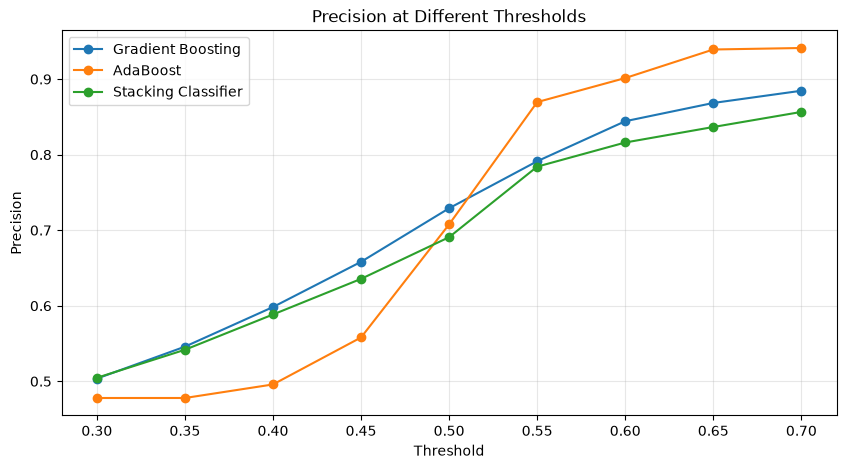

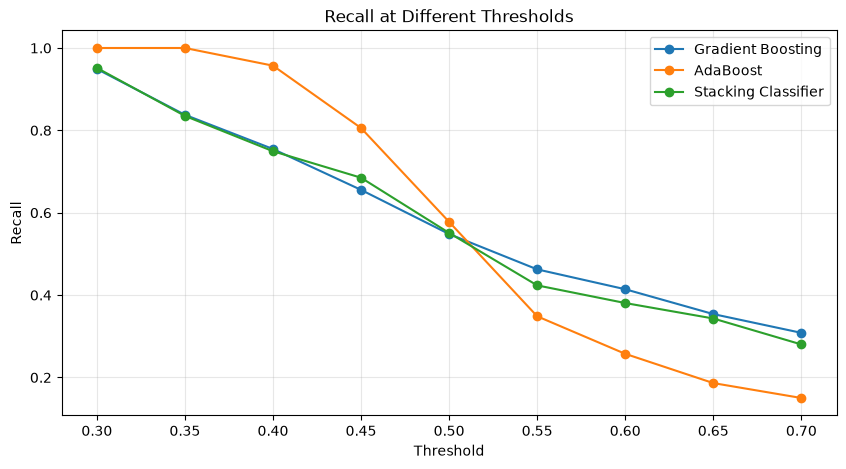

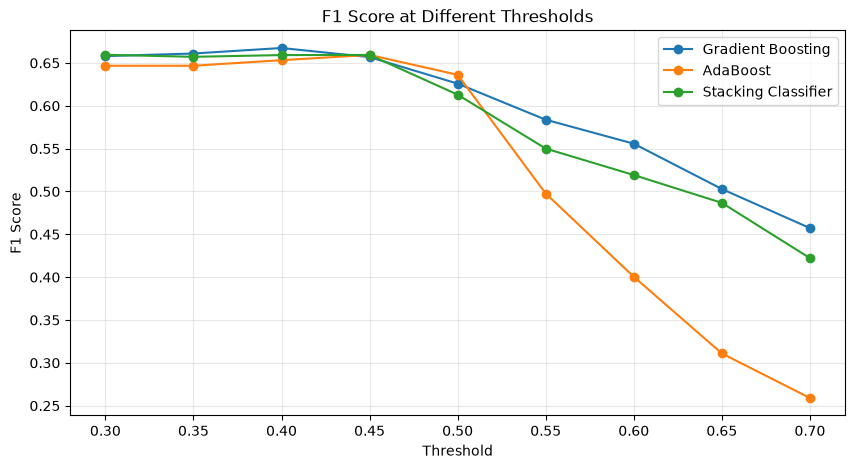

In [60]:
import matplotlib.pyplot as plt

metrics = ['Precision', 'Recall', 'F1 Score']

for metric in metrics:

    plt.figure(figsize=(10, 5))

    for name in threshold_df['Model'].unique():

        model_data = threshold_df[
            threshold_df['Model'] == name
        ]

        plt.plot(
            model_data['Threshold'],
            model_data[metric],
            marker='o',
            label=name
        )

    plt.title(f'{metric} at Different Thresholds')
    plt.xlabel('Threshold')
    plt.ylabel(metric)
    plt.xticks(thresholds)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

**Threshold Optimization Results**

Berdasarkan hasil Threshold Optimization dengan menguji threshold antara 0.30 hingga 0.70, diperoleh bahwa setiap model memiliki threshold optimal yang berbeda berdasarkan nilai F1 Score tertinggi.

**Gradient Boosting** memperoleh threshold optimal sebesar **0.40** dengan Accuracy sebesar 0.6406, Precision sebesar 0.5983, Recall sebesar 0.7547, dan F1 Score sebesar **0.6675**. Hasil ini menunjukkan bahwa Gradient Boosting memiliki keseimbangan terbaik antara Precision dan Recall dibandingkan dua model lainnya. Penurunan threshold dari 0.50 menjadi 0.40 meningkatkan Recall dari 0.5483 menjadi 0.7547, meskipun Precision mengalami penurunan dari 0.7291 menjadi 0.5983.

**Stacking Classifier** memperoleh threshold optimal sebesar **0.30** dengan Accuracy sebesar 0.5304, Precision sebesar 0.5046, Recall sebesar **0.9517**, dan F1 Score sebesar 0.6595. Hasil ini menunjukkan bahwa Stacking Classifier mampu mengidentifikasi sebagian besar nasabah yang benar-benar berlangganan deposito. Namun, nilai Precision yang relatif rendah menunjukkan bahwa model juga menghasilkan lebih banyak prediksi positif yang tidak sesuai dengan kondisi sebenarnya.

**AdaBoost** memperoleh threshold optimal sebesar **0.45** dengan Accuracy sebesar 0.6022, Precision sebesar 0.5580, Recall sebesar 0.8056, dan F1 Score sebesar 0.6594. Penurunan threshold dari 0.50 menjadi 0.45 meningkatkan Recall dari 0.5777 menjadi 0.8056, dengan konsekuensi penurunan Precision. Hasil ini menunjukkan bahwa AdaBoost mampu menemukan lebih banyak nasabah potensial dibandingkan pada threshold default.

Berdasarkan perbandingan tersebut, Gradient Boosting memperoleh F1 Score tertinggi sebesar 0.6675, sehingga menjadi model dengan keseimbangan Precision dan Recall terbaik berdasarkan threshold yang diuji. Sementara itu, Stacking Classifier memiliki Recall tertinggi sebesar 0.9517, sehingga dapat menjadi alternatif apabila prioritas bisnis lebih menekankan pada upaya meminimalkan nasabah potensial yang terlewatkan.

Dengan demikian, Gradient Boosting menjadi kandidat utama berdasarkan F1 Score, sedangkan AdaBoost dan Stacking Classifier tetap menjadi alternatif dengan karakteristik performa yang berbeda. Pemilihan model dan threshold akhir tetap perlu mempertimbangkan kebutuhan bisnis sebelum dilakukan evaluasi menggunakan test set.

## **11. FINAL MODEL EVALUATION**

In [61]:
# Model dan threshold terpilih dari validation set

final_candidates = {
    'Gradient Boosting': {
        'model': tuning_results['Gradient Boosting'].best_estimator_,
        'threshold': 0.40
    },
    'AdaBoost': {
        'model': tuning_results['AdaBoost'].best_estimator_,
        'threshold': 0.45
    },
    'Stacking Classifier': {
        'model': tuning_results['Stacking Classifier'].best_estimator_,
        'threshold': 0.30
    }
}

In [62]:
# Menyimpan hasil evaluasi
final_results = []
confusion_matrices = {}

for name, candidate in final_candidates.items():

    model = candidate['model']
    threshold = candidate['threshold']

    # Prediksi probabilitas kelas positif
    y_proba = model.predict_proba(X_test)[:, 1]

    # Prediksi berdasarkan threshold terpilih
    y_pred = [
        'yes' if prob >= threshold else 'no'
        for prob in y_proba
    ]

    # Menghitung evaluation metrics
    final_results.append({
        'Model': name,
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(
            y_test, y_pred,
            pos_label='yes',
            zero_division=0
        ),
        'Recall': recall_score(
            y_test, y_pred,
            pos_label='yes',
            zero_division=0
        ),
        'F1 Score': f1_score(
            y_test, y_pred,
            pos_label='yes',
            zero_division=0
        ),
        'ROC AUC': roc_auc_score(
            y_test.map({'no': 0, 'yes': 1}),
            y_proba
        )
    })

    # Menyimpan Confusion Matrix
    confusion_matrices[name] = confusion_matrix(
        y_test,
        y_pred,
        labels=['no', 'yes']
    )

# Membuat DataFrame hasil evaluasi
final_df = pd.DataFrame(final_results)

display(
    final_df.sort_values(
        by='ROC AUC',
        ascending=False
    ).reset_index(drop=True)
)

,Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,AdaBoost,0.45,0.631006,0.582046,0.808311,0.676768,0.745171
1,Gradient Boosting,0.40,0.668802,0.629966,0.743968,0.682237,0.740230
2,Stacking Classifier,0.30,0.530429,0.504666,0.942359,0.657317,0.731850


**Final Model Evaluation**

Pada proses pengembangan model, test set tidak digunakan untuk fitting, tuning, maupun threshold optimization pada konfigurasi final. Namun, karena data test pernah digunakan dalam proses eksperimen model, hasil evaluasi masih memiliki keterbatasan. Oleh karena itu, diperlukan pengujian lebih lanjut menggunakan data kampanye baru.  

Berdasarkan hasil evaluasi validation set, Gradient Boosting dipilih sebagai kandidat utama dengan threshold 0.40 karena memperoleh F1 Score tertinggi sebesar 0.6675. Sementara itu, AdaBoost dan Stacking Classifier tetap dievaluasi sebagai model pembanding dengan threshold masing-masing sebesar 0.45 dan 0.30.

Evaluasi dilakukan menggunakan Accuracy, Precision, Recall, F1 Score, dan ROC AUC. Selain itu, Confusion Matrix digunakan untuk melihat distribusi prediksi benar dan salah pada masing-masing kelas.

Hasil evaluasi ini akan menjadi dasar untuk menilai kemampuan generalisasi model serta menentukan apakah performa yang diperoleh pada validation set dapat dipertahankan ketika model dihadapkan pada data yang belum pernah dilihat sebelumnya.

## **12.CONFUSION MATRIX**

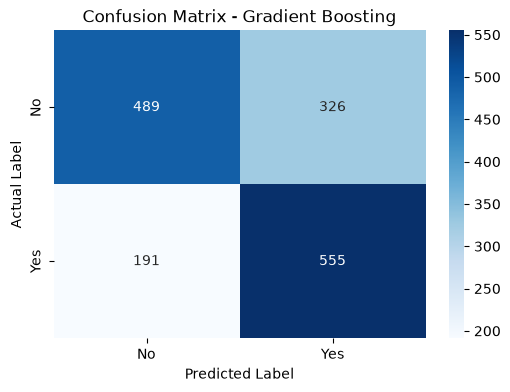

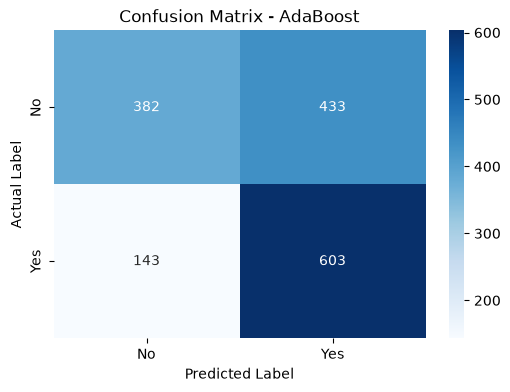

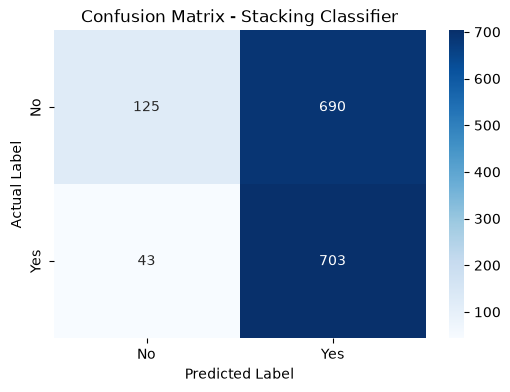

In [63]:
for name, cm in confusion_matrices.items():

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No', 'Yes'],
        yticklabels=['No', 'Yes']
    )

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('Actual Label')
    plt.show()

**Confusion Matrix Interpretation**

Berdasarkan hasil evaluasi menggunakan Confusion Matrix pada test set, diperoleh perbedaan karakteristik prediksi dari ketiga model yang diuji.

**Gradient Boosting** dengan threshold 0.40 menghasilkan 489 True Negative, 326 False Positive, 191 False Negative, dan 555 True Positive. Hasil ini menunjukkan bahwa model mampu mengidentifikasi 555 nasabah yang benar-benar berlangganan deposito, sementara 191 nasabah positif masih gagal teridentifikasi. Di sisi lain, model juga berhasil mengklasifikasikan 489 nasabah yang tidak berlangganan secara tepat.

**AdaBoost** dengan threshold 0.45 menghasilkan 382 True Negative, 433 False Positive, 143 False Negative, dan 603 True Positive. Dibandingkan Gradient Boosting, AdaBoost berhasil mengidentifikasi lebih banyak nasabah yang benar-benar berlangganan deposito dan menghasilkan jumlah False Negative yang lebih rendah. Namun, peningkatan tersebut disertai dengan jumlah False Positive yang lebih tinggi, yaitu 433 nasabah.

**Stacking Classifier** dengan threshold 0.30 menghasilkan 125 True Negative, 690 False Positive, 43 False Negative, dan 703 True Positive. Model ini memiliki jumlah True Positive tertinggi sekaligus False Negative terendah di antara ketiga model. Hal tersebut menunjukkan kemampuan yang sangat tinggi dalam menangkap nasabah yang benar-benar berlangganan deposito. Namun, jumlah False Positive yang mencapai 690 menunjukkan bahwa model juga cenderung mengklasifikasikan banyak nasabah yang tidak berlangganan sebagai nasabah potensial.

Secara keseluruhan, hasil Confusion Matrix menunjukkan bahwa setiap model memiliki karakteristik prediksi yang berbeda. Gradient Boosting memberikan hasil yang relatif lebih seimbang, AdaBoost mampu mengidentifikasi lebih banyak nasabah potensial dibandingkan Gradient Boosting, sedangkan Stacking Classifier lebih berorientasi pada peningkatan identifikasi kelas positif dengan konsekuensi meningkatnya jumlah False Positive.

**Final Model**

In [64]:
display(
    final_df.sort_values(
        by='ROC AUC',
        ascending=False
    ).reset_index(drop=True)
)

,Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,AdaBoost,0.45,0.631006,0.582046,0.808311,0.676768,0.745171
1,Gradient Boosting,0.40,0.668802,0.629966,0.743968,0.682237,0.740230
2,Stacking Classifier,0.30,0.530429,0.504666,0.942359,0.657317,0.731850


**Final Model Evaluation Results**

Berdasarkan hasil evaluasi pada test set, AdaBoost memperoleh nilai ROC AUC tertinggi sebesar **0.7452**, diikuti oleh Gradient Boosting sebesar **0.7402** dan Stacking Classifier sebesar **0.7319**. Hasil ini menunjukkan bahwa AdaBoost memiliki kemampuan diskriminasi terbaik dalam membedakan nasabah yang berlangganan deposito dan yang tidak berlangganan berdasarkan ROC AUC.

Dari sisi Accuracy, Gradient Boosting memperoleh nilai tertinggi sebesar **0.6688**, diikuti oleh AdaBoost sebesar 0.6310 dan Stacking Classifier sebesar 0.5304. Gradient Boosting juga memperoleh Precision tertinggi sebesar **0.6300**, yang menunjukkan bahwa prediksi positif yang dihasilkan memiliki proporsi kebenaran paling tinggi di antara ketiga model.

Sementara itu, AdaBoost memperoleh Recall sebesar **0.8083**, lebih tinggi dibandingkan Gradient Boosting sebesar 0.7440. Hal ini menunjukkan bahwa AdaBoost mampu mengidentifikasi lebih banyak nasabah yang benar-benar berlangganan deposito. Namun, peningkatan Recall tersebut disertai dengan Precision yang lebih rendah.

Stacking Classifier memperoleh Recall tertinggi sebesar **0.9424**, tetapi memiliki Accuracy dan Precision paling rendah. Hal ini menunjukkan bahwa model cenderung mengklasifikasikan lebih banyak nasabah sebagai calon pelanggan positif, sehingga menghasilkan jumlah False Positive yang relatif tinggi.

Berdasarkan F1 Score, Gradient Boosting memperoleh nilai tertinggi sebesar **0.6822**, diikuti oleh AdaBoost sebesar 0.6768 dan Stacking Classifier sebesar 0.6573. Hasil ini menunjukkan bahwa Gradient Boosting memberikan keseimbangan terbaik antara Precision dan Recall pada threshold yang telah ditentukan berdasarkan validation set.

**Final Model Selection**  

Berdasarkan hasil evaluasi pada validation set dan threshold optimization, Gradient Boosting dipilih sebagai kandidat final model karena memperoleh F1 Score tertinggi sebesar 0.6675. Pemilihan ini dilakukan sebelum pengujian menggunakan test set untuk menghindari pemilihan model berdasarkan hasil test set.

Pada tahap Final Model Evaluation, hasil pengujian menunjukkan bahwa Gradient Boosting tetap memperoleh F1 Score tertinggi sebesar 0.6822. Hasil tersebut menunjukkan bahwa Gradient Boosting juga memberikan performa yang baik pada test set dibandingkan dua model lainnya.

Meskipun AdaBoost memperoleh ROC AUC sedikit lebih tinggi, yaitu 0.7452 dibandingkan Gradient Boosting sebesar 0.7402, Gradient Boosting tetap dipertahankan sebagai final model berdasarkan kriteria pemilihan yang telah ditetapkan sebelumnya, yaitu F1 Score tertinggi pada validation set.

## **13. FEATURE IMPORTANCE & MODEL INTERPRETATION**  

Tahap Feature Importance dilakukan untuk mengidentifikasi fitur-fitur yang memiliki kontribusi terhadap kemampuan model dalam memprediksi potensi nasabah berlangganan deposito.

Pada tahap ini digunakan metode **Permutation Importance** untuk mengukur perubahan performa model ketika nilai suatu fitur diacak. Apabila pengacakan suatu fitur menyebabkan penurunan performa model, fitur tersebut dianggap memiliki kontribusi terhadap kemampuan prediksi model.

Analisis dilakukan menggunakan model Gradient Boosting yang telah dipilih sebagai final model berdasarkan hasil evaluasi. ROC AUC digunakan sebagai scoring metric untuk mengukur perubahan kemampuan diskriminasi model setelah dilakukan pengacakan fitur.

Hasil analisis ini diharapkan dapat memberikan pemahaman mengenai fitur-fitur yang berkontribusi terhadap prediksi potensi nasabah serta memberikan insight yang dapat dipertimbangkan oleh tim marketing dalam menyusun strategi pemasaran.

In [65]:
from sklearn.inspection import permutation_importance

# Mengambil final model Gradient Boosting
final_model = tuning_results['Gradient Boosting'].best_estimator_

# Menghitung Permutation Importance
perm_importance = permutation_importance(
    final_model,
    X_val,
    y_val,
    scoring='roc_auc',
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

# Membuat DataFrame hasil Feature Importance
feature_importance_df = pd.DataFrame({
    'Feature': X_val.columns,
    'Importance Mean': perm_importance.importances_mean,
    'Importance Std': perm_importance.importances_std
})

feature_importance_df = feature_importance_df.sort_values(
    by='Importance Mean',
    ascending=False
).reset_index(drop=True)

display(feature_importance_df)

,Feature,Importance Mean,Importance Std
0,poutcome,0.053804,0.007118
1,housing,0.037074,0.007631
2,age,0.029488,0.007452
3,pdays,0.022836,0.004861
4,balance,0.020786,0.006450
5,loan,0.007370,0.002433
6,job,0.001968,0.002503
7,age_group,0.000889,0.000698
8,previously_contacted,0.000000,0.000000


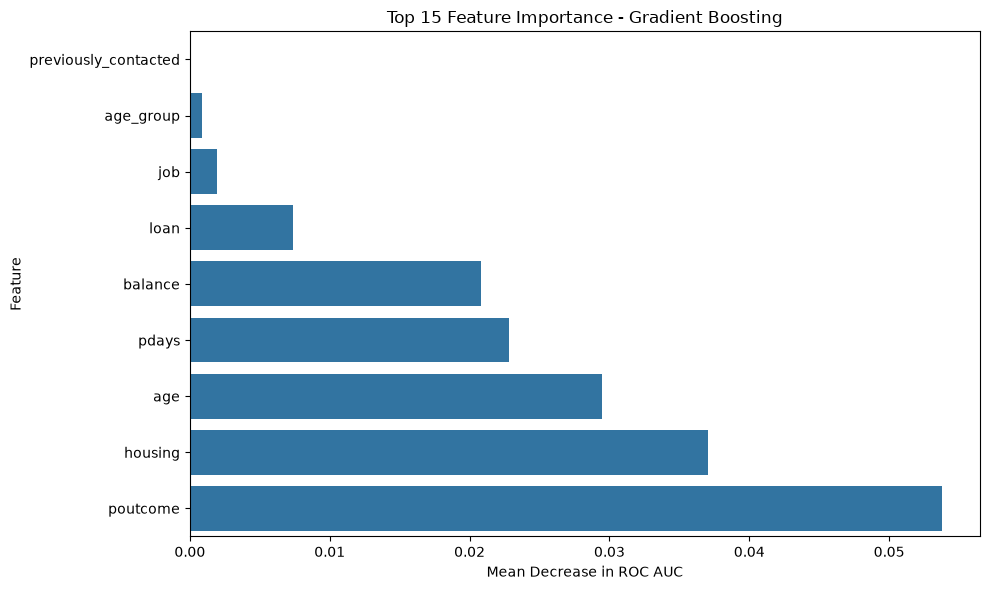

In [66]:
top_features = feature_importance_df.head(15).sort_values(
    by='Importance Mean',
    ascending=True
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x='Importance Mean',
    y='Feature'
)

plt.title('Top 15 Feature Importance - Gradient Boosting')
plt.xlabel('Mean Decrease in ROC AUC')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

**Feature Importance Results**

Berdasarkan hasil analisis menggunakan Permutation Importance pada model Gradient Boosting, diperoleh bahwa fitur **`poutcome`** memiliki nilai importance tertinggi sebesar **0.053804** dengan standar deviasi 0.007118. Hasil ini menunjukkan bahwa pengacakan nilai `poutcome` menyebabkan penurunan performa ROC AUC paling besar dibandingkan fitur lainnya. Dengan demikian, informasi mengenai hasil kampanye pemasaran sebelumnya memberikan kontribusi paling besar terhadap kemampuan prediksi model.

Fitur **`housing`** menempati posisi kedua dengan nilai importance sebesar **0.037074**, diikuti oleh **`age`** sebesar 0.029488. Hal ini menunjukkan bahwa informasi kepemilikan pinjaman perumahan dan usia nasabah juga berkontribusi terhadap kemampuan model dalam membedakan nasabah yang berpotensi berlangganan deposito dan yang tidak.

Selanjutnya, fitur **`pdays`** memperoleh nilai importance sebesar 0.022836, sedangkan **`balance`** memperoleh nilai sebesar 0.020786. Kedua fitur tersebut memberikan kontribusi terhadap performa model melalui informasi mengenai riwayat waktu kontak pada kampanye sebelumnya dan kondisi saldo nasabah.

Sementara itu, fitur **`loan`** memperoleh nilai importance sebesar 0.007370 dan **`job`** sebesar 0.001968. Adapun fitur turunan **`age_group`** memiliki nilai importance sebesar 0.000889, yang menunjukkan kontribusi relatif kecil terhadap performa model.

Fitur **`previously_contacted`** memperoleh nilai importance sebesar 0.000000 dengan standar deviasi 0.000000. Hasil ini menunjukkan bahwa pengacakan fitur tersebut tidak mengubah performa ROC AUC model pada pengujian ini. Salah satu kemungkinan penyebabnya adalah informasi yang terkandung di dalam fitur tersebut telah terwakili oleh fitur `pdays`, sehingga kontribusi tambahannya menjadi sangat kecil.

Secara keseluruhan, hasil Permutation Importance menunjukkan bahwa `poutcome`, `housing`, `age`, `pdays`, dan `balance` merupakan lima fitur dengan kontribusi terbesar terhadap performa model Gradient Boosting. Temuan ini dapat menjadi dasar untuk memahami karakteristik nasabah yang digunakan model dalam menghasilkan prediksi potensi berlangganan deposito.

## **14. INTERPRETABLE ML using SHAP** 

In [67]:
import shap

# Mengambil final model
final_model = tuning_results['Gradient Boosting'].best_estimator_

# Memisahkan preprocessing dan classifier
preprocessor = final_model.named_steps['preprocessor']
classifier = final_model.named_steps['model']

# Transformasi validation set
X_val_transformed = preprocessor.transform(X_val)

# Mengubah sparse matrix menjadi dense array jika diperlukan
if hasattr(X_val_transformed, 'toarray'):
    X_val_transformed = X_val_transformed.toarray()

# Mengambil nama fitur setelah preprocessing
feature_names = preprocessor.get_feature_names_out()

# Membuat DataFrame hasil transformasi
X_val_transformed_df = pd.DataFrame(
    X_val_transformed,
    columns=feature_names,
    index=X_val.index
)

display(X_val_transformed_df.head())

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,num__age,num__balance,num__pdays,cat__job_admin.,cat__job_blue-collar,cat__job_entrepreneur,cat__job_housemaid,cat__job_management,cat__job_retired,cat__job_self-employed,...,cat__poutcome_success,cat__poutcome_unknown,cat__age_group_Adult,cat__age_group_Elderly,cat__age_group_Mature Adult,cat__age_group_Middle Adult,cat__age_group_Senior,cat__age_group_Young Adult,cat__previously_contacted_no,cat__previously_contacted_yes
1811,1.470588,0.014071,0.000000,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2110,-0.529412,0.441318,0.000000,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
7676,1.705882,-0.351135,0.000000,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1626,-0.235294,-0.347298,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1882,0.058824,12.020467,3.396226,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [68]:
explainer = shap.TreeExplainer(classifier)

shap_values = explainer.shap_values(
    X_val_transformed_df
)

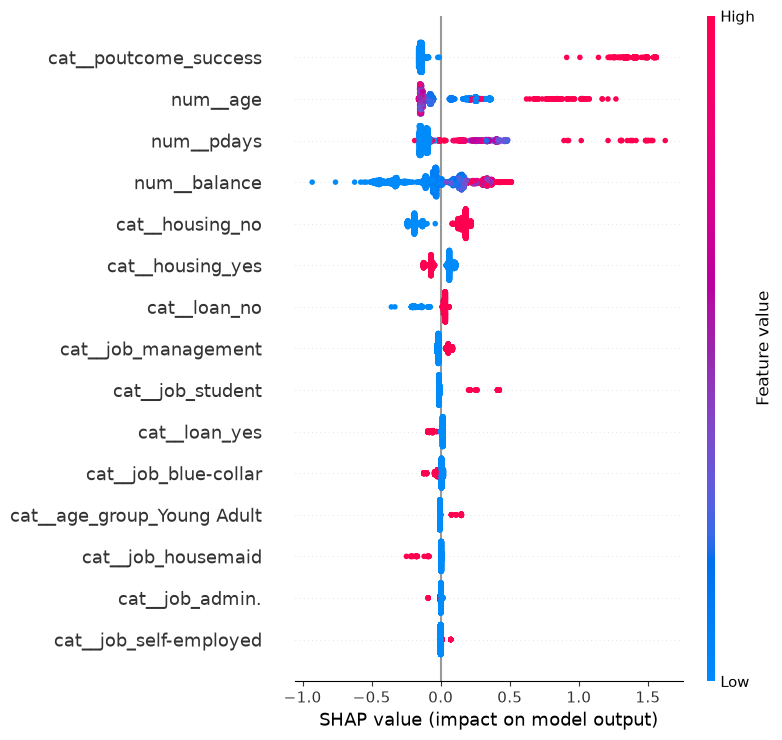

In [69]:
shap.summary_plot(
    shap_values,
    X_val_transformed_df,
    max_display=15
)

**SHAP Summary Plot Interpretation**

Berdasarkan hasil interpretasi menggunakan SHAP Summary Plot pada model Gradient Boosting, fitur `poutcome_success` menunjukkan pengaruh paling dominan terhadap output prediksi model. Titik dengan nilai fitur tinggi (merah), yang merepresentasikan nasabah dengan hasil kampanye sebelumnya yang sukses, cenderung memiliki SHAP value positif. Hal ini menunjukkan bahwa kategori tersebut cenderung mendorong output model ke arah prediksi nasabah berlangganan deposito.

Fitur `age` juga menunjukkan kontribusi yang cukup besar. Nilai usia yang lebih tinggi cenderung memiliki SHAP value positif, sedangkan beberapa nilai usia yang lebih rendah berada di sekitar nilai nol atau sisi negatif. Temuan ini menunjukkan bahwa usia menjadi salah satu karakteristik yang dipertimbangkan model dalam menghasilkan prediksi, meskipun pengaruhnya tidak sepenuhnya bersifat linear.

Selanjutnya, fitur `pdays` menunjukkan bahwa nilai yang lebih tinggi cenderung memberikan kontribusi positif terhadap output model. Sementara itu, nilai yang lebih rendah, termasuk nilai -1 yang merepresentasikan nasabah yang belum pernah dihubungi sebelumnya, lebih banyak terkonsentrasi di sekitar nol atau sisi negatif.

Fitur `balance` juga memperlihatkan pola bahwa nilai saldo yang lebih tinggi cenderung mendorong output model ke arah positif, sedangkan nilai saldo yang lebih rendah lebih banyak memberikan kontribusi negatif. Meskipun demikian, distribusi SHAP value menunjukkan bahwa pengaruh saldo tidak selalu sama pada seluruh observasi.

Pada fitur kategorikal, `housing_no` cenderung memberikan kontribusi positif ketika bernilai 1, sedangkan `housing_yes` cenderung memberikan kontribusi negatif ketika bernilai 1. Hal ini menunjukkan bahwa model cenderung memberikan output prediksi lebih positif pada nasabah yang tidak memiliki pinjaman perumahan dibandingkan nasabah yang memiliki pinjaman perumahan.

Fitur lainnya, seperti `loan_no`, `job_management`, `job_student`, dan `age_group_Young Adult`, juga memberikan kontribusi terhadap output model, tetapi pengaruhnya relatif lebih kecil dibandingkan fitur-fitur utama.

Secara keseluruhan, hasil SHAP Summary Plot menunjukkan bahwa informasi hasil kampanye sebelumnya, usia, riwayat kontak, saldo, dan status kepemilikan pinjaman perumahan merupakan karakteristik yang cukup berpengaruh dalam pembentukan prediksi model Gradient Boosting. Hasil ini menggambarkan pola yang dipelajari model dari data dan tidak dapat diartikan sebagai hubungan sebab-akibat.

## **15. CONCLUSION AND RECOMMENDATION**

**CONCLUSION**

Berdasarkan seluruh tahapan analisis dan pemodelan yang telah dilakukan, proyek ini bertujuan membangun model Machine Learning untuk memprediksi potensi nasabah dalam berlangganan deposito berjangka (*term deposit*) sebelum kampanye pemasaran dimulai. Model dikembangkan menggunakan pendekatan supervised learning dengan algoritma klasifikasi untuk membantu tim marketing dalam menentukan prioritas nasabah berdasarkan karakteristik dan riwayat kampanye sebelumnya.

Proses pemodelan dilakukan dengan membandingkan sepuluh algoritma klasifikasi menggunakan 5-Fold Stratified Cross Validation. Berdasarkan hasil baseline modeling, Gradient Boosting, AdaBoost, dan Stacking Classifier dipilih sebagai kandidat untuk tahap Hyperparameter Tuning. Setelah proses optimasi dan evaluasi pada validation set, ketiga model kemudian diuji menggunakan test set dengan threshold yang telah ditentukan sebelumnya.

Berdasarkan hasil evaluasi akhir, **Gradient Boosting dipilih sebagai final model** dengan threshold sebesar **0.40**. Model tersebut memperoleh Accuracy sebesar **0.6688**, Precision sebesar **0.6300**, Recall sebesar **0.7440**, F1 Score sebesar **0.6822**, dan ROC AUC sebesar **0.7402** pada test set.

Hasil tersebut menunjukkan bahwa Gradient Boosting memberikan keseimbangan terbaik antara Precision dan Recall berdasarkan F1 Score dibandingkan dua kandidat lainnya. Model mampu mengidentifikasi sekitar 74.40% nasabah yang benar-benar berlangganan deposito, dengan tingkat ketepatan prediksi positif sebesar 63.00%.

Selain evaluasi performa, analisis Feature Importance dan SHAP menunjukkan bahwa `poutcome`, `housing`, `age`, `pdays`, dan `balance` merupakan fitur yang memberikan kontribusi relatif besar terhadap prediksi model. Temuan ini menunjukkan bahwa riwayat kampanye sebelumnya dan karakteristik nasabah menjadi informasi penting yang dipelajari model dalam memperkirakan potensi berlangganan deposito.

Dengan demikian, model Gradient Boosting dapat digunakan sebagai alat bantu pengambilan keputusan bagi tim marketing untuk mengidentifikasi dan memprioritaskan nasabah potensial sebelum kampanye pemasaran dilaksanakan. Namun, hasil prediksi tetap merupakan estimasi berdasarkan pola historis dan bukan jaminan bahwa nasabah akan benar-benar berlangganan deposito.

### **BUSINESS RECOMENDATIONS**

Berdasarkan hasil pemodelan, terdapat beberapa rekomendasi yang dapat dipertimbangkan oleh pihak bank dalam memanfaatkan model prediksi ini.

1. Prioritization of Potential Customers

Tim marketing dapat menggunakan probabilitas prediksi Gradient Boosting untuk mengelompokkan nasabah berdasarkan potensi berlangganan deposito. Nasabah dengan probabilitas prediksi lebih tinggi dapat diprioritaskan untuk mendapatkan penawaran pemasaran terlebih dahulu.

2. More Efficient Marketing Resource Allocation

Model dapat membantu tim marketing mengalokasikan waktu, tenaga, dan biaya kampanye secara lebih terarah. Dengan adanya prediksi potensi nasabah, proses pemilihan target pemasaran tidak hanya bergantung pada pendekatan umum, tetapi juga mempertimbangkan pola yang dipelajari dari data historis.

3. Utilizing Previous Campaign Information

Hasil interpretasi model menunjukkan bahwa poutcome memiliki kontribusi paling besar terhadap performa prediksi. Oleh karena itu, bank dapat mempertimbangkan riwayat hasil kampanye sebelumnya sebagai salah satu informasi pendukung dalam menyusun strategi pemasaran berikutnya.

4. Continuous Model Performance Monitoring

Model perlu dievaluasi secara berkala menggunakan data kampanye terbaru. Monitoring dapat dilakukan dengan memperhatikan ROC AUC, Precision, Recall, dan F1 Score untuk mengetahui apakah performa model masih sesuai dengan kebutuhan bisnis.

5. Conducting Campaign Experiments

Bank disarankan melakukan pengujian kampanye secara terkontrol, misalnya melalui A/B testing, untuk mengetahui apakah penggunaan model benar-benar meningkatkan tingkat konversi dibandingkan strategi pemasaran yang tidak menggunakan model prediksi.

Hasil pengujian tersebut dapat digunakan untuk mengukur dampak implementasi model terhadap proses bisnis secara lebih objektif.

### **MODEL LIMITATIONS**

Meskipun model Gradient Boosting memberikan performa terbaik berdasarkan F1 Score pada test set, terdapat beberapa keterbatasan yang perlu diperhatikan sebelum model diterapkan dalam lingkungan bisnis.

1. Historical Data Dependency

Model dibangun berdasarkan data historis kampanye pemasaran. Oleh karena itu, pola yang dipelajari belum tentu sepenuhnya merepresentasikan perilaku nasabah pada periode pemasaran yang berbeda. Perubahan kondisi ekonomi, preferensi nasabah, maupun strategi pemasaran dapat memengaruhi performa model.

2. Prediction Performance

Model memperoleh F1 Score sebesar 0.6822 dan ROC AUC sebesar 0.7402 pada test set. Hasil ini menunjukkan bahwa model memiliki kemampuan diskriminasi dan klasifikasi yang cukup baik, tetapi masih terdapat kesalahan prediksi. Model belum dapat menjamin seluruh nasabah potensial berhasil diidentifikasi secara tepat.

3. False Positive and False Negative

Berdasarkan Confusion Matrix, model menghasilkan 326 False Positive dan 191 False Negative. False Positive dapat menyebabkan tim marketing menghubungi nasabah yang pada akhirnya tidak berlangganan deposito. Sementara itu, False Negative menunjukkan adanya nasabah potensial yang tidak berhasil diidentifikasi oleh model.

4. Feature Availability

Model menggunakan informasi seperti pdays dan poutcome yang berasal dari riwayat kampanye sebelumnya. Ketersediaan kedua fitur tersebut sebelum kampanye baru dimulai perlu dipastikan dalam implementasi sebenarnya. Apabila informasi tersebut tidak tersedia pada waktu prediksi, model tidak dapat digunakan dengan konfigurasi fitur yang sama.

5. Threshold Dependency

Model menggunakan threshold sebesar 0.40 yang dipilih berdasarkan hasil evaluasi validation set. Penggunaan threshold tersebut menghasilkan trade-off antara Precision dan Recall. Perubahan kebutuhan bisnis, kapasitas tim marketing, maupun biaya kampanye dapat memerlukan penyesuaian threshold melalui proses validasi ulang.

6. Model Validation Scope

Evaluasi dilakukan menggunakan pembagian data training, validation, dan test. Selain itu, test set juga pernah digunakan dalam eksperimen dengan konfigurasi fitur sebelumnya. Oleh karena itu, hasil evaluasi revisi perlu ditafsirkan dengan mempertimbangkan riwayat penggunaan data tersebut dan belum dapat dianggap sebagai validasi temporal yang sepenuhnya independen.

Dengan mempertimbangkan keterbatasan tersebut, model sebaiknya digunakan sebagai alat bantu pengambilan keputusan dan tetap memerlukan evaluasi serta pemantauan secara berkala.

### **FUTURE IMPROVEMENTS**

Untuk meningkatkan kualitas model dan efektivitas implementasinya, beberapa pengembangan yang dapat dilakukan pada proyek selanjutnya adalah:

1. **Additional Customer Information:** menambahkan informasi nasabah yang lebih relevan, seperti riwayat transaksi, pola penggunaan produk perbankan, dan interaksi nasabah dengan layanan bank, apabila tersedia dan diizinkan untuk digunakan.

2. **Temporal Validation:** menerapkan pembagian data berdasarkan periode waktu kampanye untuk menguji kemampuan model dalam memprediksi nasabah pada periode yang lebih baru.

3. **Model Optimization:** mengeksplorasi algoritma dan konfigurasi hyperparameter lainnya untuk meningkatkan kemampuan prediksi serta generalisasi model.

4. **Threshold Optimization Based on Business Costs:** menentukan threshold berdasarkan kapasitas tim marketing, biaya menghubungi nasabah, dan potensi keuntungan dari nasabah yang berhasil berlangganan deposito.

5. **Model Deployment:** mengembangkan model ke dalam aplikasi berbasis Streamlit agar tim marketing dapat memasukkan informasi nasabah dan memperoleh probabilitas prediksi secara lebih praktis.

6. **Model Monitoring and Retraining:** melakukan pemantauan performa model secara berkala dan melakukan pelatihan ulang apabila ditemukan perubahan pola data atau penurunan performa prediksi.

Melalui pengembangan tersebut, model diharapkan dapat menjadi solusi pendukung keputusan yang lebih adaptif, relevan, dan bermanfaat bagi proses pemasaran produk deposito.

# **DEPLOYMENT**

### **1. Final Model Refit**

Setelah menentukan Gradient Boosting sebagai final model berdasarkan hasil evaluasi validation set, model dilatih ulang menggunakan gabungan data training dan validation. Proses ini bertujuan untuk memanfaatkan lebih banyak data dalam membangun model final sebelum dilakukan deployment.

In [70]:
from sklearn.base import clone 


# Mengambil best estimator Gradient Boosting
best_gb_model = tuning_results['Gradient Boosting'].best_estimator_

# Menggabungkan data training dan validation
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

# Membuat salinan pipeline
final_model = clone(best_gb_model)

# Melatih ulang model
final_model.fit(X_train_val, y_train_val)

print("Final Gradient Boosting model berhasil dilatih ulang!")

Final Gradient Boosting model berhasil dilatih ulang!


### **2. Saving Final Model**

Final model disimpan menggunakan library Joblib agar dapat digunakan kembali tanpa perlu melakukan proses training ulang ketika aplikasi Streamlit dijalankan.

In [71]:
import joblib

# Konfigurasi model
model_artifact = {
    'model': final_model,
    'threshold': 0.40,
    'features': list(X_train.columns)
}

# Menyimpan model dan konfigurasi
joblib.dump(model_artifact, 'bank_marketing_model.joblib')

print("Model berhasil disimpan!")

Model berhasil disimpan!


In [72]:
# Load model
loaded_artifact = joblib.load('bank_marketing_model.joblib')

# Mengambil model dan threshold
loaded_model = loaded_artifact['model']
loaded_threshold = loaded_artifact['threshold']

print("Model:", type(loaded_model.named_steps['model']).__name__)
print("Threshold:", loaded_threshold)
print("Features:", loaded_artifact['features'])

Model: GradientBoostingClassifier
Threshold: 0.4
Features: ['age', 'job', 'balance', 'housing', 'loan', 'pdays', 'poutcome', 'age_group', 'previously_contacted']
